# Domain Analysis

# Bussiness Case:-
 * Create a predictive model  using machine learning techniques to predict the various classes of skin disease

## DataSet Information


#### Class

*  1: psoriasis
*  2: seboreic dermatitis
*  3: lichen planus
*  4: pityriasis rosea
*  5: cronic dermatitis
*  6: pityriasis rubra pilaris

#### Family history:

*  1: if any of these diseases has been observed in the family
*  0: otherwise

#### Age:

*  Represents the age of the patient

#### All other attributes:

*  0: feature not present
*  1,2 indicate the relative intermediate values
*  3 indicates the largest amount possible

In [1]:
import pandas as pd # Importing Pandas for data manipulation and analysis
import numpy as np # Importing NumPy for numerical calculations and array operations
import matplotlib.pyplot as plt # Importing Matplotlib for creating graphs and visualizations
import seaborn as sns # Importing Seaborn for creating attractive statistical graphs
import warnings # Importing the warnings module to manage warning messages
warnings.filterwarnings("ignore") # Ignoring warning messages to keep the output clean

In [2]:
pd.set_option("display.max_columns",None) # show total columns

In [3]:
df = pd.read_csv("Skin_DisOrder_Prediction.csv") # Loading the Skin Disorder Prediction CSV dataset into a Df variable

In [4]:
df.head()# showing first 5 row of the data

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,family_history,melanin_incontinence,eosinophils_in_the_infiltrate,PNL_infiltrate,fibrosis_of_the_papillary_dermis,exocytosis,acanthosis,hyperkeratosis,parakeratosis,clubbing_of_the_rete_ridges,elongation_of_the_rete_ridges,thinning_of_the_suprapapillary_epidermis,spongiform_pustule,munro_microabcess,focal_hypergranulosis,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age,class
0,2,2,0,3,0,0,0,0,1,0,0,0,0,0,0,3,2,0,0,0,0,0,0,0,0,0,0,3,0,0,0,1,0,55,2
1,3,3,3,2,1,0,0,0,1,1,1,0,0,1,0,1,2,0,2,2,2,2,2,1,0,0,0,0,0,0,0,1,0,8,1
2,2,1,2,3,1,3,0,3,0,0,0,1,0,0,0,1,2,0,2,0,0,0,0,0,2,0,2,3,2,0,0,2,3,26,3
3,2,2,2,0,0,0,0,0,3,2,0,0,0,3,0,0,2,0,3,2,2,2,2,0,0,3,0,0,0,0,0,3,0,40,1
4,2,3,2,2,2,2,0,2,0,0,0,1,0,0,0,1,2,0,0,0,0,0,0,0,2,2,3,2,3,0,0,2,3,45,3


In [5]:
df.tail() # showing last 5 row of the data

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,family_history,melanin_incontinence,eosinophils_in_the_infiltrate,PNL_infiltrate,fibrosis_of_the_papillary_dermis,exocytosis,acanthosis,hyperkeratosis,parakeratosis,clubbing_of_the_rete_ridges,elongation_of_the_rete_ridges,thinning_of_the_suprapapillary_epidermis,spongiform_pustule,munro_microabcess,focal_hypergranulosis,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age,class
361,2,1,1,0,1,0,0,0,0,0,0,0,0,1,0,1,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,2,0,25,4
362,3,2,1,0,1,0,0,0,0,0,0,0,0,0,0,2,2,0,0,0,0,0,0,0,0,1,0,1,0,0,0,2,0,36,4
363,3,2,2,2,3,2,0,2,0,0,0,2,2,0,0,3,3,0,0,0,0,0,0,0,3,0,3,0,3,0,0,2,3,28,3
364,2,1,3,1,2,3,0,2,0,0,0,2,0,0,0,3,2,0,0,0,0,0,0,0,3,0,2,0,1,0,0,2,3,50,3
365,3,2,2,0,0,0,0,0,3,3,0,0,0,1,0,0,2,0,2,3,2,3,0,2,0,2,0,0,0,0,0,3,0,35,1


In [6]:
df.shape # show all records and features

(366, 35)

In [7]:
df.info() #dataset information of each and every columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 366 entries, 0 to 365
Data columns (total 35 columns):
 #   Column                                    Non-Null Count  Dtype 
---  ------                                    --------------  ----- 
 0   erythema                                  366 non-null    int64 
 1   scaling                                   366 non-null    int64 
 2   definite_borders                          366 non-null    int64 
 3   itching                                   366 non-null    int64 
 4   koebner_phenomenon                        366 non-null    int64 
 5   polygonal_papules                         366 non-null    int64 
 6   follicular_papules                        366 non-null    int64 
 7   oral_mucosal_involvement                  366 non-null    int64 
 8   knee_and_elbow_involvement                366 non-null    int64 
 9   scalp_involvement                         366 non-null    int64 
 10  family_history                            366 non-

#### Insights

* Age column is in object,we have to convert in integers.

In [8]:
df.columns # shows columns names

Index(['erythema', 'scaling', 'definite_borders', 'itching',
       'koebner_phenomenon', 'polygonal_papules', 'follicular_papules',
       'oral_mucosal_involvement', 'knee_and_elbow_involvement',
       'scalp_involvement', 'family_history', 'melanin_incontinence',
       'eosinophils_in_the_infiltrate', 'PNL_infiltrate',
       'fibrosis_of_the_papillary_dermis', 'exocytosis', 'acanthosis',
       'hyperkeratosis', 'parakeratosis', 'clubbing_of_the_rete_ridges',
       'elongation_of_the_rete_ridges',
       'thinning_of_the_suprapapillary_epidermis', 'spongiform_pustule',
       'munro_microabcess', 'focal_hypergranulosis',
       'disappearance_of_the_granular_layer',
       'vacuolisation_and_damage_of_basal_layer', 'spongiosis',
       'saw-tooth_appearance_of_retes', 'follicular_horn_plug',
       'perifollicular_parakeratosis', 'inflammatory_monoluclear_inflitrate',
       'band-like_infiltrate', 'Age', 'class'],
      dtype='object')

In [9]:
df.dtypes # Display the data type of each column in the DataFrame

erythema                                     int64
scaling                                      int64
definite_borders                             int64
itching                                      int64
koebner_phenomenon                           int64
polygonal_papules                            int64
follicular_papules                           int64
oral_mucosal_involvement                     int64
knee_and_elbow_involvement                   int64
scalp_involvement                            int64
family_history                               int64
melanin_incontinence                         int64
eosinophils_in_the_infiltrate                int64
PNL_infiltrate                               int64
fibrosis_of_the_papillary_dermis             int64
exocytosis                                   int64
acanthosis                                   int64
hyperkeratosis                               int64
parakeratosis                                int64
clubbing_of_the_rete_ridges    

In [10]:
df.isnull().sum() # Count the number of missing (null) values in each column of the DataFrame

erythema                                    0
scaling                                     0
definite_borders                            0
itching                                     0
koebner_phenomenon                          0
polygonal_papules                           0
follicular_papules                          0
oral_mucosal_involvement                    0
knee_and_elbow_involvement                  0
scalp_involvement                           0
family_history                              0
melanin_incontinence                        0
eosinophils_in_the_infiltrate               0
PNL_infiltrate                              0
fibrosis_of_the_papillary_dermis            0
exocytosis                                  0
acanthosis                                  0
hyperkeratosis                              0
parakeratosis                               0
clubbing_of_the_rete_ridges                 0
elongation_of_the_rete_ridges               0
thinning_of_the_suprapapillary_epi

In [11]:
df.isnull().sum().sum() #Dataset contains no missing values.

np.int64(0)

In [12]:
df.duplicated().sum()  # Count duplicate rows in the dataset

np.int64(0)

In [13]:
df.describe() # statistical information only numerical columns

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,family_history,melanin_incontinence,eosinophils_in_the_infiltrate,PNL_infiltrate,fibrosis_of_the_papillary_dermis,exocytosis,acanthosis,hyperkeratosis,parakeratosis,clubbing_of_the_rete_ridges,elongation_of_the_rete_ridges,thinning_of_the_suprapapillary_epidermis,spongiform_pustule,munro_microabcess,focal_hypergranulosis,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,class
count,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000
mean,2.068306,1.795082,1.549180,1.366120,0.633880,0.448087,0.166667,0.377049,0.614754,0.519126,0.125683,0.404372,0.139344,0.546448,0.336066,1.368852,1.956284,0.527322,1.289617,0.663934,0.991803,0.633880,0.295082,0.363388,0.393443,0.464481,0.456284,0.953552,0.453552,0.103825,0.114754,1.866120,0.554645,2.803279
std,0.664753,0.701527,0.907525,1.138299,0.908016,0.957327,0.570588,0.834147,0.982979,0.905639,0.331946,0.869818,0.411790,0.815451,0.853139,1.104418,0.712512,0.757116,0.917562,1.056829,1.162161,1.034924,0.670578,0.759721,0.849406,0.864899,0.954873,1.130172,0.954744,0.450433,0.488723,0.726108,1.105908,1.597803
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000
50%,2.000000,2.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,2.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,3.000000
75%,2.000000,2.000000,2.000000,2.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,2.000000,2.000000,1.000000,2.000000,2.000000,2.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000,0.000000,0.000000,2.000000,0.000000,4.000000
max,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,1.000000,3.000000,2.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,6.000000


In [14]:
df["class"].value_counts()# Target Value Counts

class
1    112
3     72
2     61
5     52
4     49
6     20
Name: count, dtype: int64

In [15]:
df["class"].value_counts(normalize=True) * 100 #Target Percentage

class
1    30.601093
3    19.672131
2    16.666667
5    14.207650
4    13.387978
6     5.464481
Name: proportion, dtype: float64

In [16]:
for col in df.columns: # Loop through all columns
    print(col, ":", df[col].unique())  # Display unique values in each column

erythema : [2 3 1 0]
scaling : [2 3 1 0]
definite_borders : [0 3 2 1]
itching : [3 2 0 1]
koebner_phenomenon : [0 1 2 3]
polygonal_papules : [0 3 2 1]
follicular_papules : [0 3 1 2]
oral_mucosal_involvement : [0 3 2 1]
knee_and_elbow_involvement : [1 0 3 2]
scalp_involvement : [0 1 2 3]
family_history : [0 1]
melanin_incontinence : [0 1 2 3]
eosinophils_in_the_infiltrate : [0 2 1]
PNL_infiltrate : [0 1 3 2]
fibrosis_of_the_papillary_dermis : [0 3 1 2]
exocytosis : [3 1 0 2]
acanthosis : [2 3 1 0]
hyperkeratosis : [0 2 1 3]
parakeratosis : [0 2 3 1]
clubbing_of_the_rete_ridges : [0 2 1 3]
elongation_of_the_rete_ridges : [0 2 3 1]
thinning_of_the_suprapapillary_epidermis : [0 2 3 1]
spongiform_pustule : [0 2 1 3]
munro_microabcess : [0 1 2 3]
focal_hypergranulosis : [0 2 3 1]
disappearance_of_the_granular_layer : [0 3 2 1]
vacuolisation_and_damage_of_basal_layer : [0 2 3 1]
spongiosis : [3 0 2 1]
saw-tooth_appearance_of_retes : [0 2 3 1]
follicular_horn_plug : [0 1 2 3]
perifollicular_pa

In [17]:
df.nunique() #Number of Unique Values

erythema                                     4
scaling                                      4
definite_borders                             4
itching                                      4
koebner_phenomenon                           4
polygonal_papules                            4
follicular_papules                           4
oral_mucosal_involvement                     4
knee_and_elbow_involvement                   4
scalp_involvement                            4
family_history                               2
melanin_incontinence                         4
eosinophils_in_the_infiltrate                3
PNL_infiltrate                               4
fibrosis_of_the_papillary_dermis             4
exocytosis                                   4
acanthosis                                   4
hyperkeratosis                               4
parakeratosis                                4
clubbing_of_the_rete_ridges                  4
elongation_of_the_rete_ridges                4
thinning_of_t

# EDA

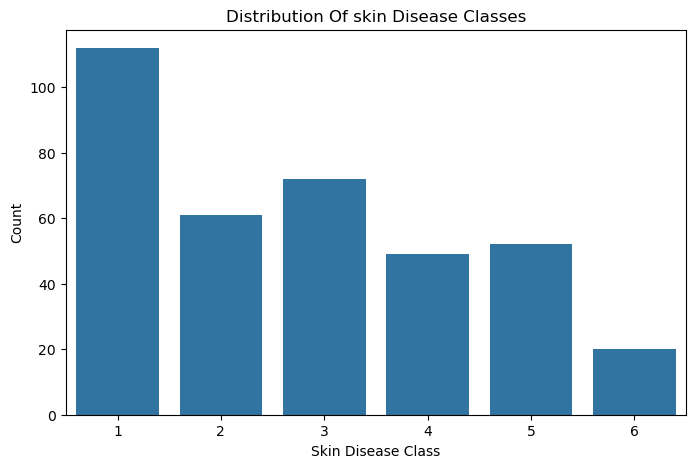

In [18]:
plt.figure(figsize=(8,5))  # Set figure size
sns.countplot(x="class",data=df) # Count samples in each class
plt.title("Distribution Of skin Disease Classes") # Set plot title
plt.xlabel("Skin Disease Class") # Set x-axis label
plt.ylabel("Count") # Set y-axis label
plt.show()  # Display the plot

### Insight:
* Shows the count and distribution of each skin disease class.

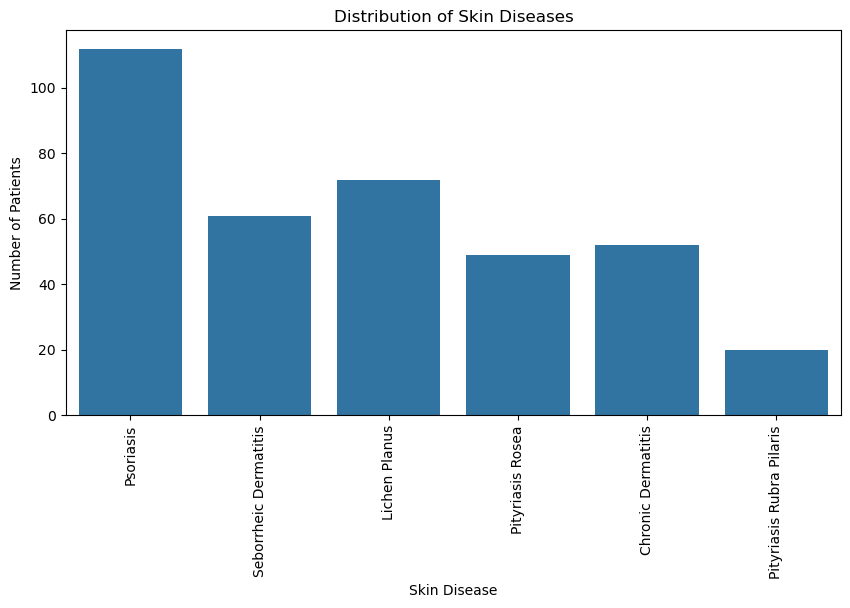

In [19]:
class_name = {1:"Psoriasis", 2:"Seborrheic Dermatitis", 3:"Lichen Planus", 4:"Pityriasis Rosea", 5:"Chronic Dermatitis", 6:"Pityriasis Rubra Pilaris"}  # Map class numbers to disease names
class_counts = df["class"].value_counts().sort_index()  # Count each class in order
plt.figure(figsize=(10,5))  # Set figure size
sns.barplot(x=class_counts.index, y=class_counts.values)  # Plot disease counts
plt.xticks(ticks=range(len(class_counts)), labels=[class_name[i] for i in class_counts.index], rotation=90)  # Display disease names
plt.title("Distribution of Skin Diseases")  # Set plot title
plt.xlabel("Skin Disease")  # Label x-axis
plt.ylabel("Number of Patients")  # Label y-axis
plt.show()  # Display graph

### Insight: 
* Shows the number of patients in each skin disease class and helps identify class imbalance.

In [20]:
print(df["class"].value_counts().sort_index())  # Count records in each class
print(df["class"].value_counts(normalize=True).sort_index() * 100)  # Calculate class percentages

class
1    112
2     61
3     72
4     49
5     52
6     20
Name: count, dtype: int64
class
1    30.601093
2    16.666667
3    19.672131
4    13.387978
5    14.207650
6     5.464481
Name: proportion, dtype: float64


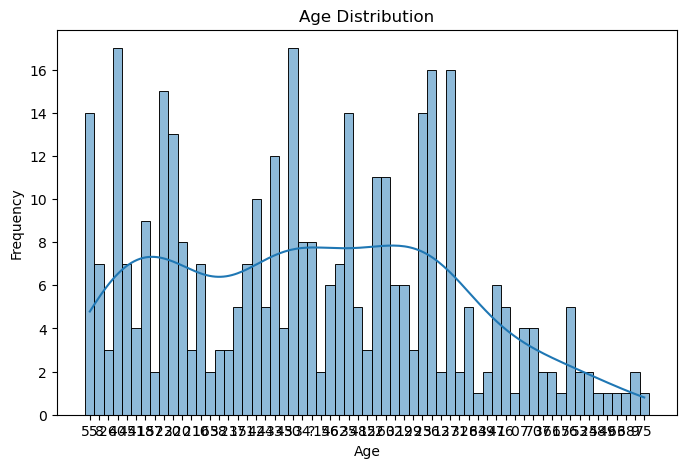

In [21]:
plt.figure(figsize=(8,5))  # Set figure size
sns.histplot(x=df.Age, kde=True)  # Plot age distribution with density curve
plt.title("Age Distribution")  # Set plot title
plt.xlabel("Age")  # Label x-axis
plt.ylabel("Frequency")  # Label y-axis
plt.show()  # Display graph

### Insight: 
* Shows the age distribution of patients and identifies the most common age range and the overall spread of ages.

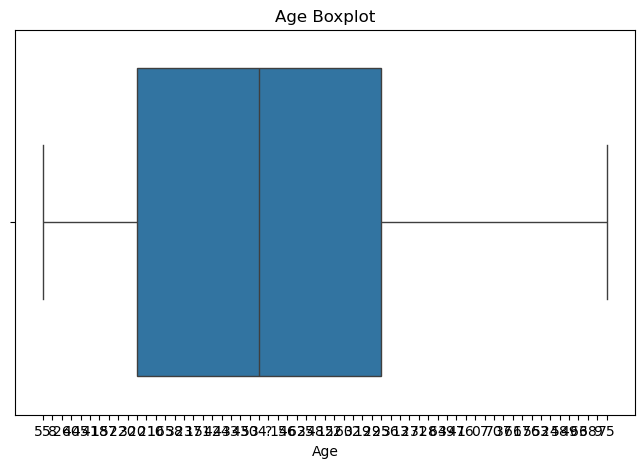

In [22]:
plt.figure(figsize=(8,5))  # Set figure size
sns.boxplot(x=df["Age"])  # Display age outliers and spread
plt.title("Age Boxplot")  # Set plot title
plt.xlabel("Age")  # Label x-axis
plt.show()  # Display graph

### Insight: 
* Identifies the age distribution, median, spread, and potential outliers in the dataset.

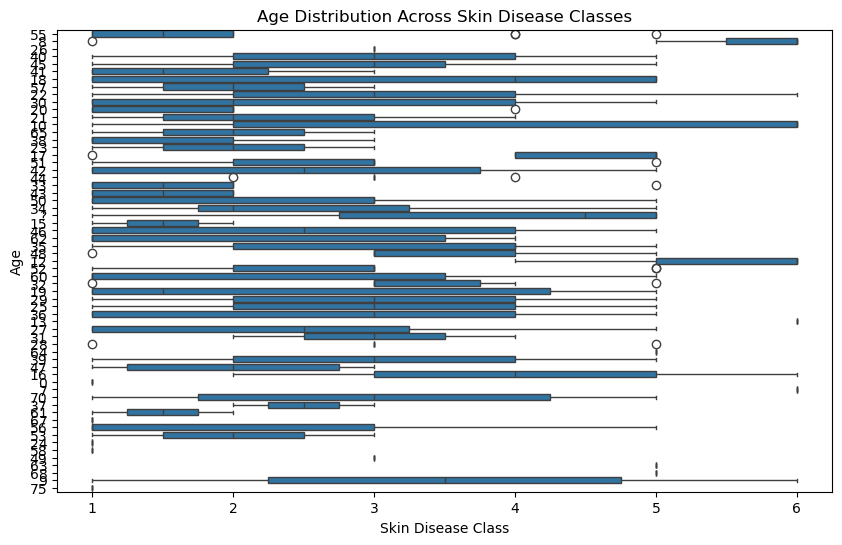

In [23]:
plt.figure(figsize=(10,6))  # Set figure size
sns.boxplot(x="class", y="Age", data=df)  # Compare age across disease classes
plt.title("Age Distribution Across Skin Disease Classes")  # Set plot title
plt.xlabel("Skin Disease Class")  # Label x-axis
plt.ylabel("Age")  # Label y-axis
plt.show()  # Display graph

### Insight: 
* Compares age distribution across skin disease classes and identifies differences in median age, spread, and potential outliers.

In [24]:
feature_cols = df.columns.drop(["Age", "class"])  # Select feature columns except Age and target

for col in feature_cols:  # Loop through each feature
    print(col, ":", sorted(df[col].unique()))  # Display sorted unique values

erythema : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
scaling : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
definite_borders : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
itching : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
koebner_phenomenon : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
polygonal_papules : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
follicular_papules : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
oral_mucosal_involvement : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
knee_and_elbow_involvement : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
scalp_involvement : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
family_history : [np.int64(0), np.int64(1)]
melanin_incontinence : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
eosinophils_in_the_infiltrate : [np.int64(0), np.int64(1), np.int64(2)]
PNL_infiltrate : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
fibrosis_of_the_papi

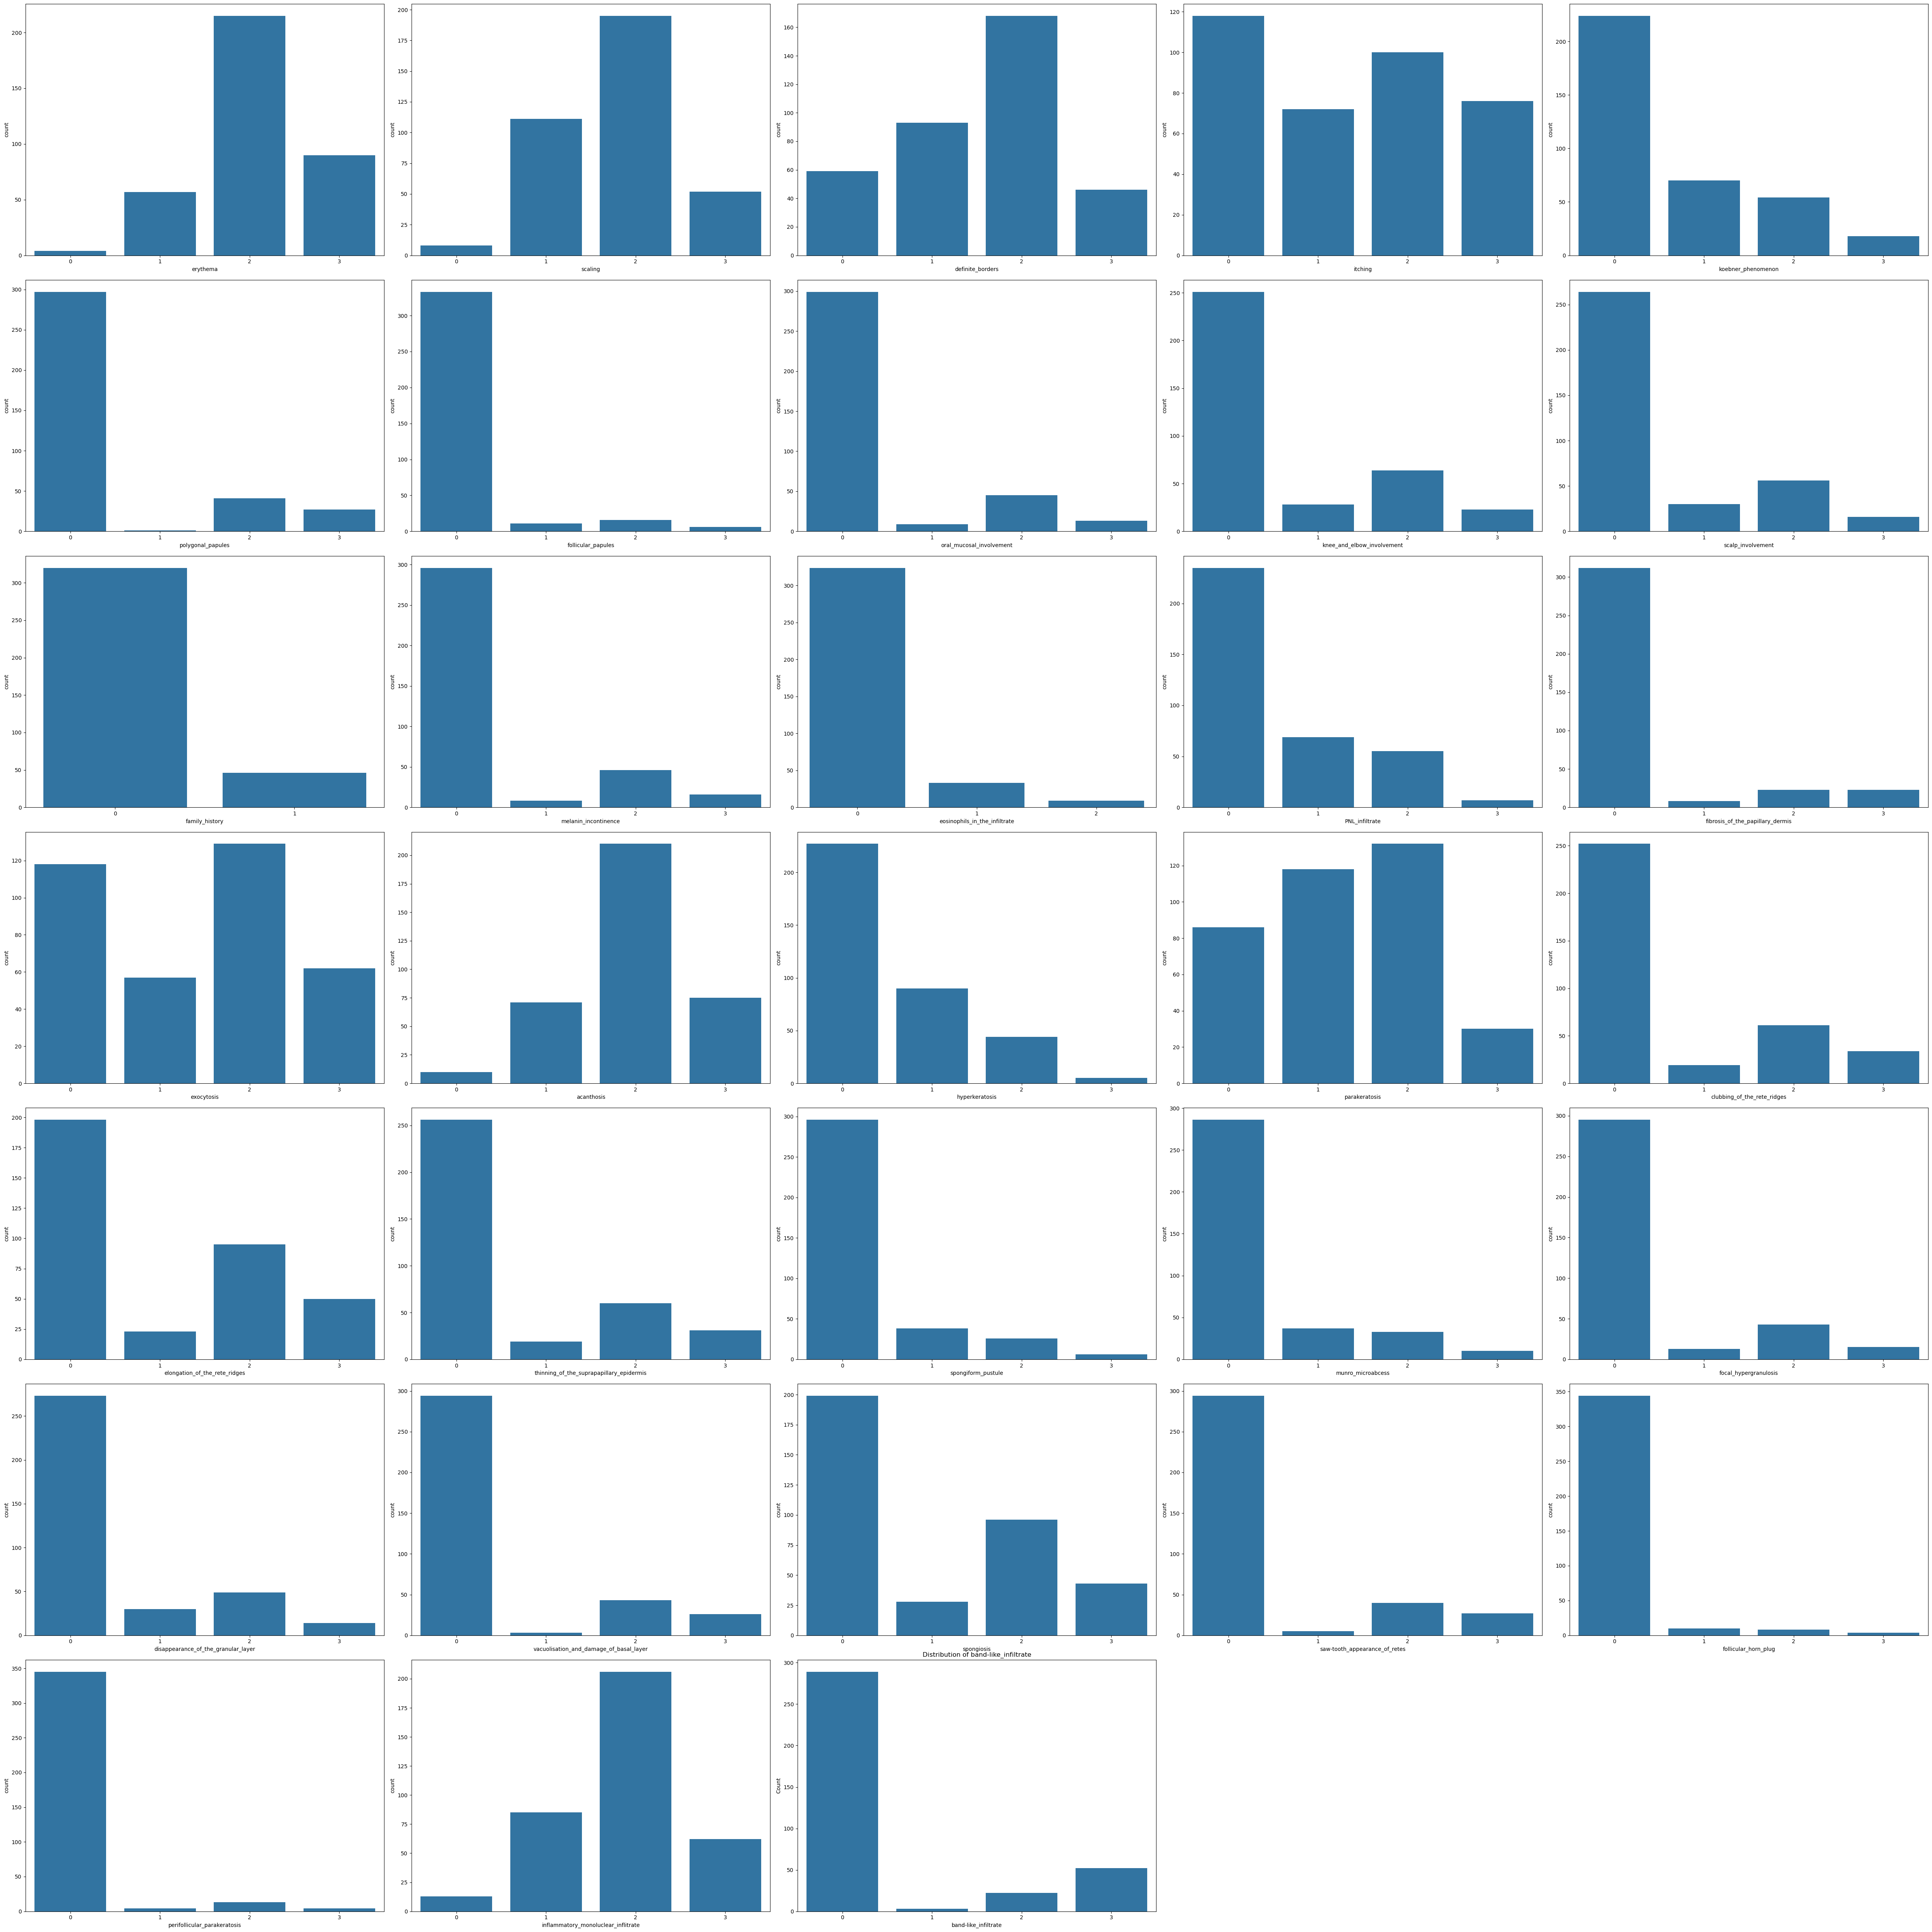

In [25]:
plt.figure(figsize=(50,50))  # Set figure size
num = 1  # Initialize subplot position
for col in feature_cols:  # Loop through feature columns
    plt.subplot(7,5,num)  # Create subplot
    sns.countplot(data=df, x=col)  # Plot feature value counts
    num = num + 1  # Move to next subplot
plt.tight_layout()  # Adjust subplot spacing
plt.title(f"Distribution of {col}")  # Set plot title
plt.xlabel(col)  # Label x-axis
plt.ylabel("Count")  # Label y-axis
plt.show()  # Display all plots

### Insight: 
* Shows the frequency distribution of each feature and helps identify common values, rare values, and potential class imbalances.

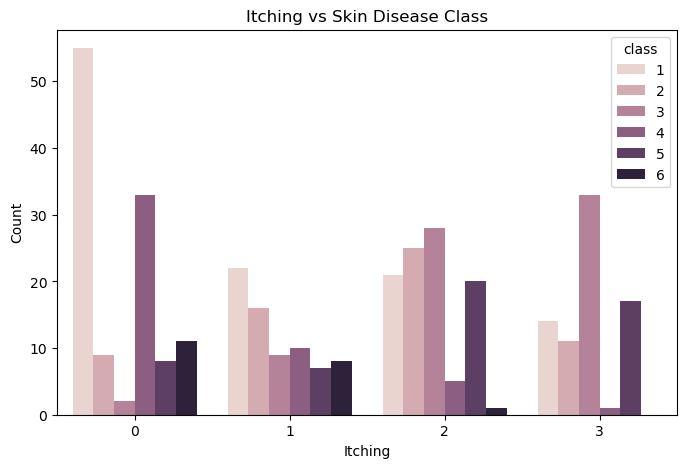

In [26]:
plt.figure(figsize=(8,5))  # Set figure size
sns.countplot(x="itching", hue="class", data=df)  # Compare itching across disease classes
plt.title("Itching vs Skin Disease Class")  # Set plot title
plt.xlabel("Itching")  # Label x-axis
plt.ylabel("Count")  # Label y-axis
plt.show()  # Display graph

### Insight: 
* Shows the relationship between itching and skin disease classes, helping identify how itching frequency varies across different diseases.

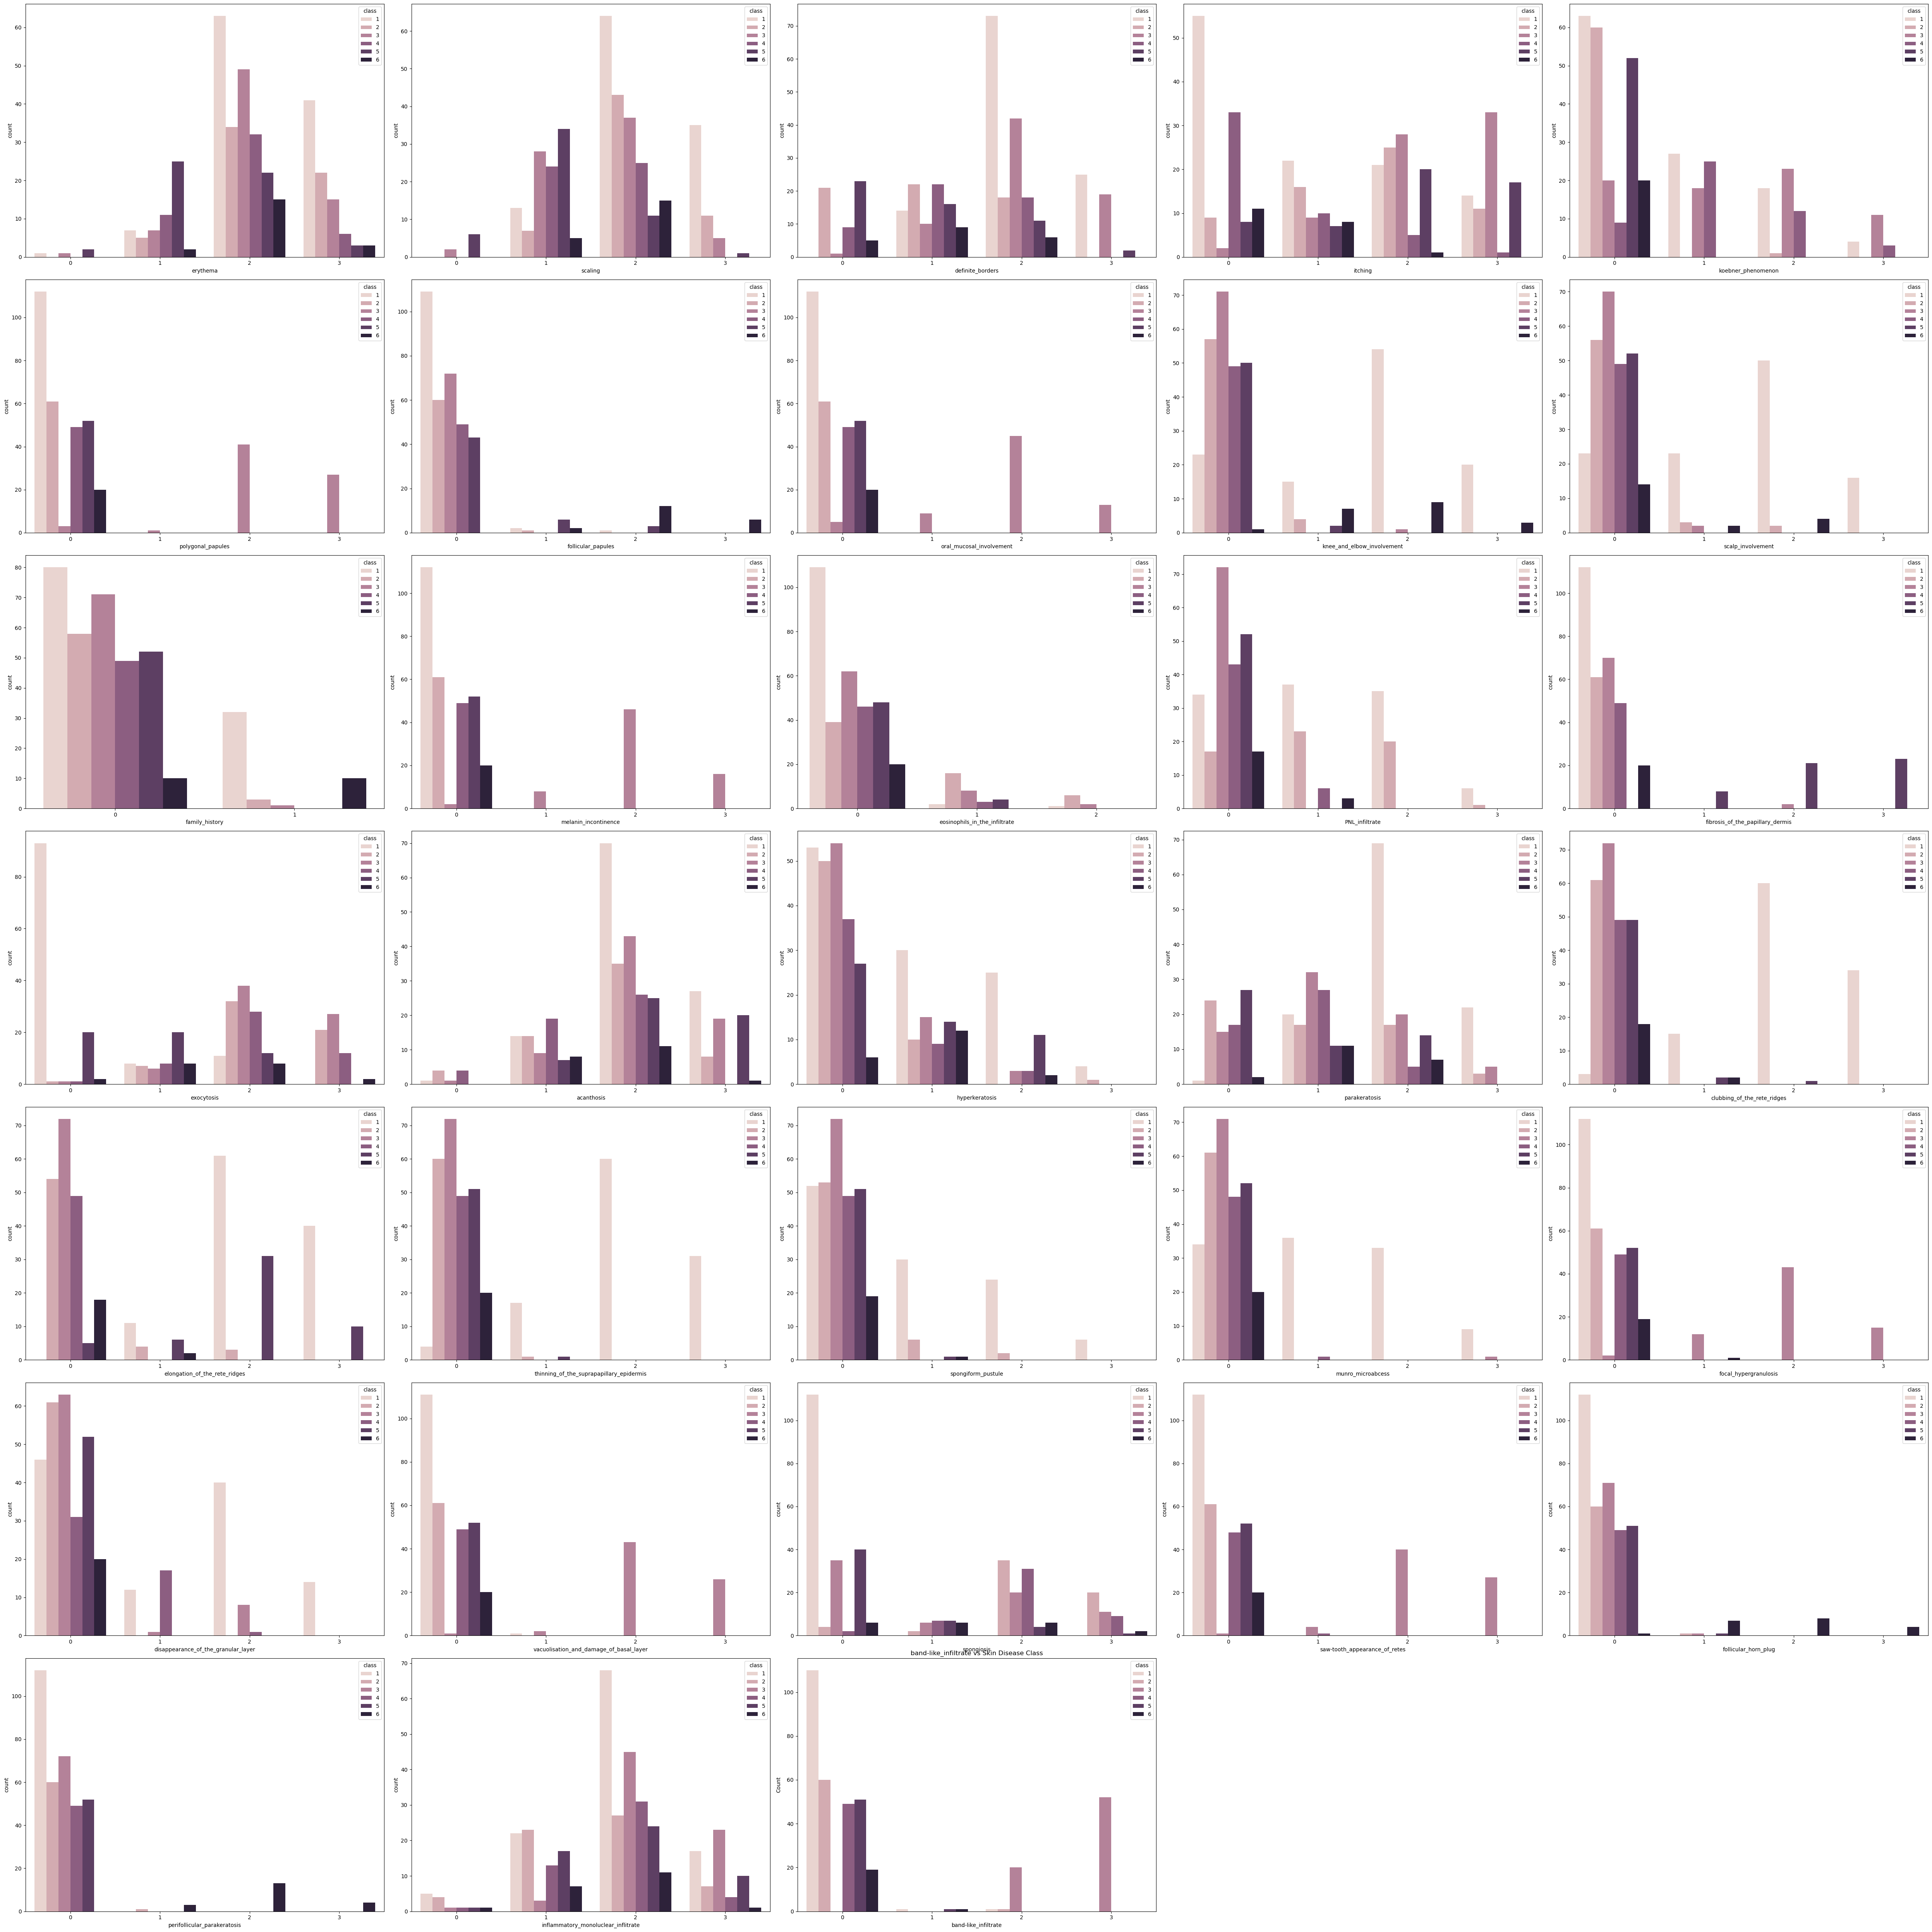

In [27]:
plt.figure(figsize=(50,50))  # Set figure size
num = 1  # Initialize subplot position
for col in feature_cols:  # Loop through feature columns
    plt.subplot(7,5,num)  # Create subplot
    sns.countplot(data=df, x=col, hue="class")  # Compare features across disease classes
    num = num + 1  # Move to next subplot
plt.tight_layout()  # Adjust subplot spacing
plt.title(f"{col} vs Skin Disease Class")  # Set plot title
plt.xlabel(col)  # Label x-axis
plt.ylabel("Count")  # Label y-axis
plt.show()  # Display all plots

### Insight: 
* Compares each feature across skin disease classes to identify patterns and symptoms that may help distinguish between diseases.

In [28]:
feature_class_mean = df.groupby("class")[feature_cols].mean()  # Calculate average feature values for each class

feature_class_mean  # Display class-wise feature averages

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,family_history,melanin_incontinence,eosinophils_in_the_infiltrate,PNL_infiltrate,fibrosis_of_the_papillary_dermis,exocytosis,acanthosis,hyperkeratosis,parakeratosis,clubbing_of_the_rete_ridges,elongation_of_the_rete_ridges,thinning_of_the_suprapapillary_epidermis,spongiform_pustule,munro_microabcess,focal_hypergranulosis,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate
class,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,2.285714,2.196429,2.098214,0.946429,0.669643,0.000000,0.035714,0.000000,1.633929,1.526786,0.285714,0.000000,0.035714,1.116071,0.000000,0.267857,2.098214,0.821429,2.000000,2.116071,2.258929,2.053571,0.857143,1.151786,0.000000,1.196429,0.008929,0.000000,0.000000,0.000000,0.000000,1.866071,0.026786
2,2.278689,2.065574,0.950820,1.622951,0.032787,0.000000,0.016393,0.000000,0.065574,0.114754,0.049180,0.000000,0.459016,1.081967,0.000000,2.196721,1.770492,0.213115,0.983607,0.000000,0.163934,0.016393,0.163934,0.000000,0.000000,0.000000,0.000000,2.163934,0.000000,0.016393,0.016393,1.606557,0.032787
3,2.083333,1.625000,2.097222,2.277778,1.347222,2.277778,0.000000,1.916667,0.027778,0.027778,0.013889,2.055556,0.166667,0.000000,0.055556,2.263889,2.111111,0.291667,1.208333,0.000000,0.000000,0.000000,0.000000,0.041667,1.986111,0.236111,2.305556,1.097222,2.291667,0.013889,0.000000,2.250000,2.722222
4,1.897959,1.510204,1.183673,0.469388,1.183673,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.061224,0.122449,0.000000,2.040816,1.448980,0.306122,0.755102,0.000000,0.000000,0.000000,0.000000,0.020408,0.000000,0.387755,0.000000,1.959184,0.020408,0.000000,0.000000,1.775510,0.000000
5,1.500000,1.134615,0.846154,1.884615,0.000000,0.000000,0.230769,0.000000,0.038462,0.000000,0.000000,0.000000,0.076923,0.000000,2.288462,0.846154,2.250000,0.692308,0.750000,0.076923,1.884615,0.019231,0.019231,0.000000,0.000000,0.000000,0.000000,0.346154,0.000000,0.019231,0.000000,1.826923,0.019231
6,2.050000,1.750000,1.050000,0.500000,0.000000,0.000000,2.200000,0.000000,1.700000,0.500000,0.500000,0.000000,0.000000,0.150000,0.000000,1.500000,1.650000,0.800000,1.250000,0.100000,0.100000,0.000000,0.050000,0.000000,0.050000,0.000000,0.000000,1.200000,0.000000,1.750000,2.050000,1.600000,0.050000


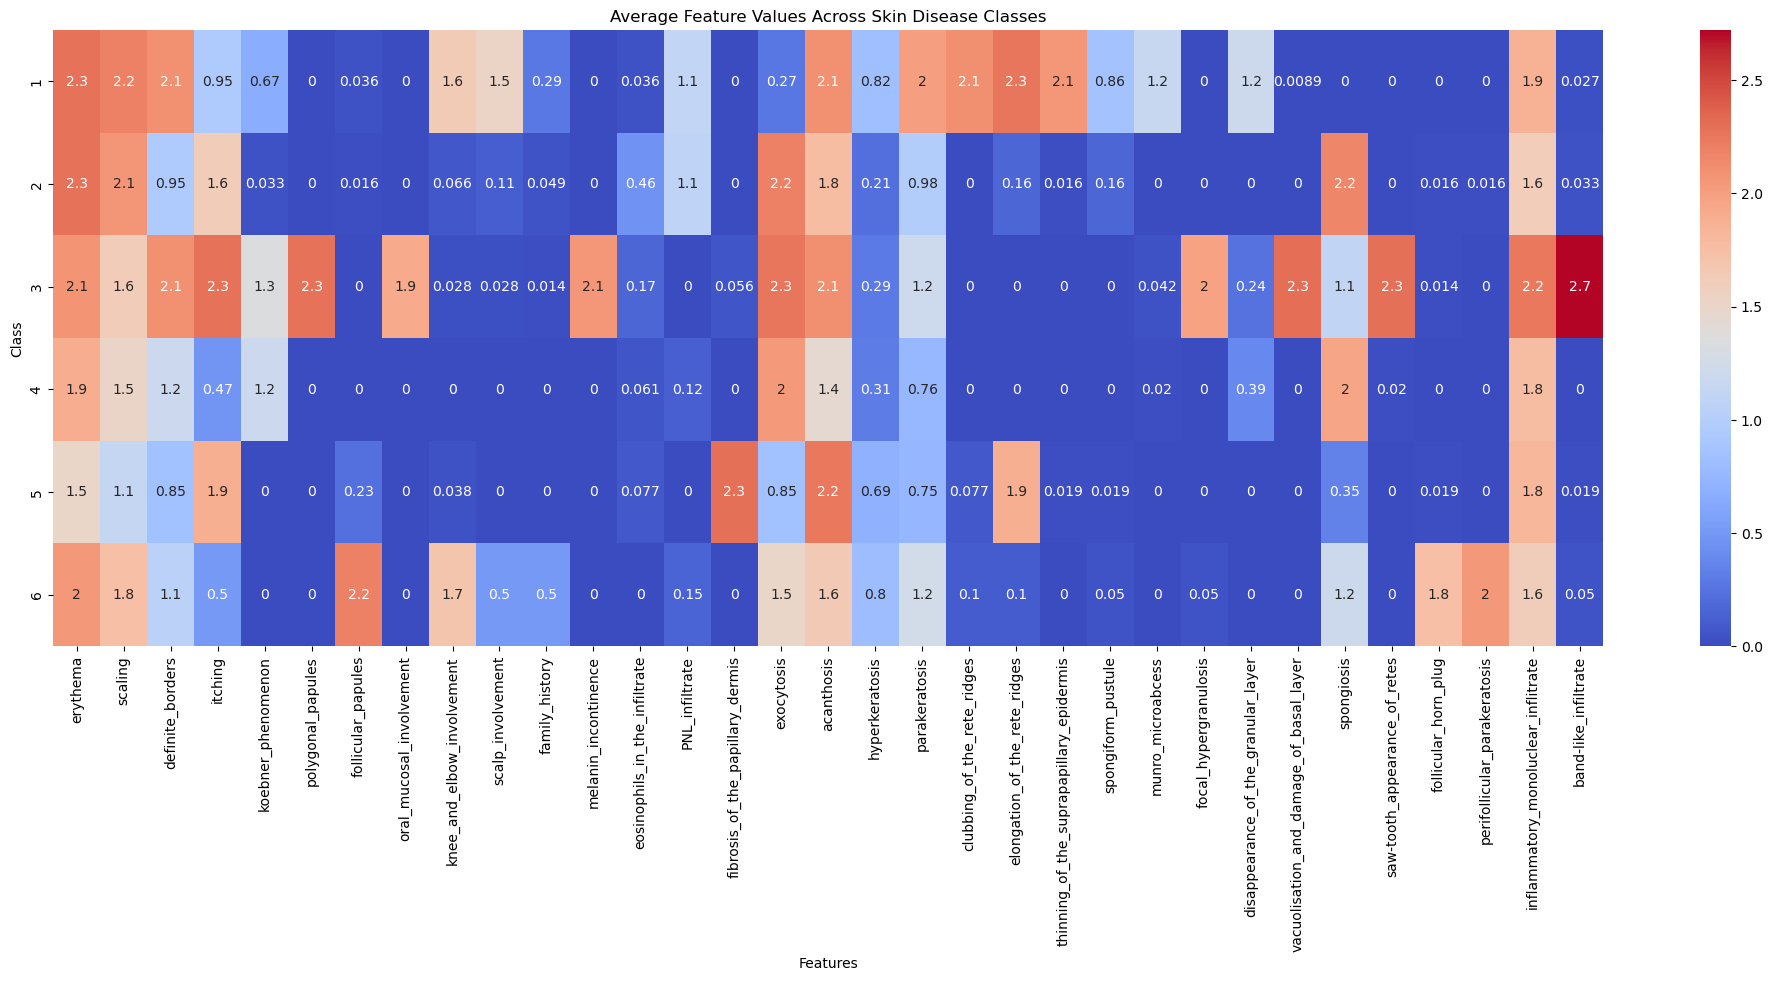

In [29]:
plt.figure(figsize=(25,8))  # Set figure size
sns.heatmap(feature_class_mean, annot=True, cmap="coolwarm")  # Display average feature values
plt.title("Average Feature Values Across Skin Disease Classes")  # Set plot title
plt.xlabel("Features")  # Label x-axis
plt.ylabel("Class")  # Label y-axis
plt.show()  # Display heatmap

### Insight: 
* Compares average feature values across skin disease classes to identify patterns and symptoms that may help distinguish between diseases.

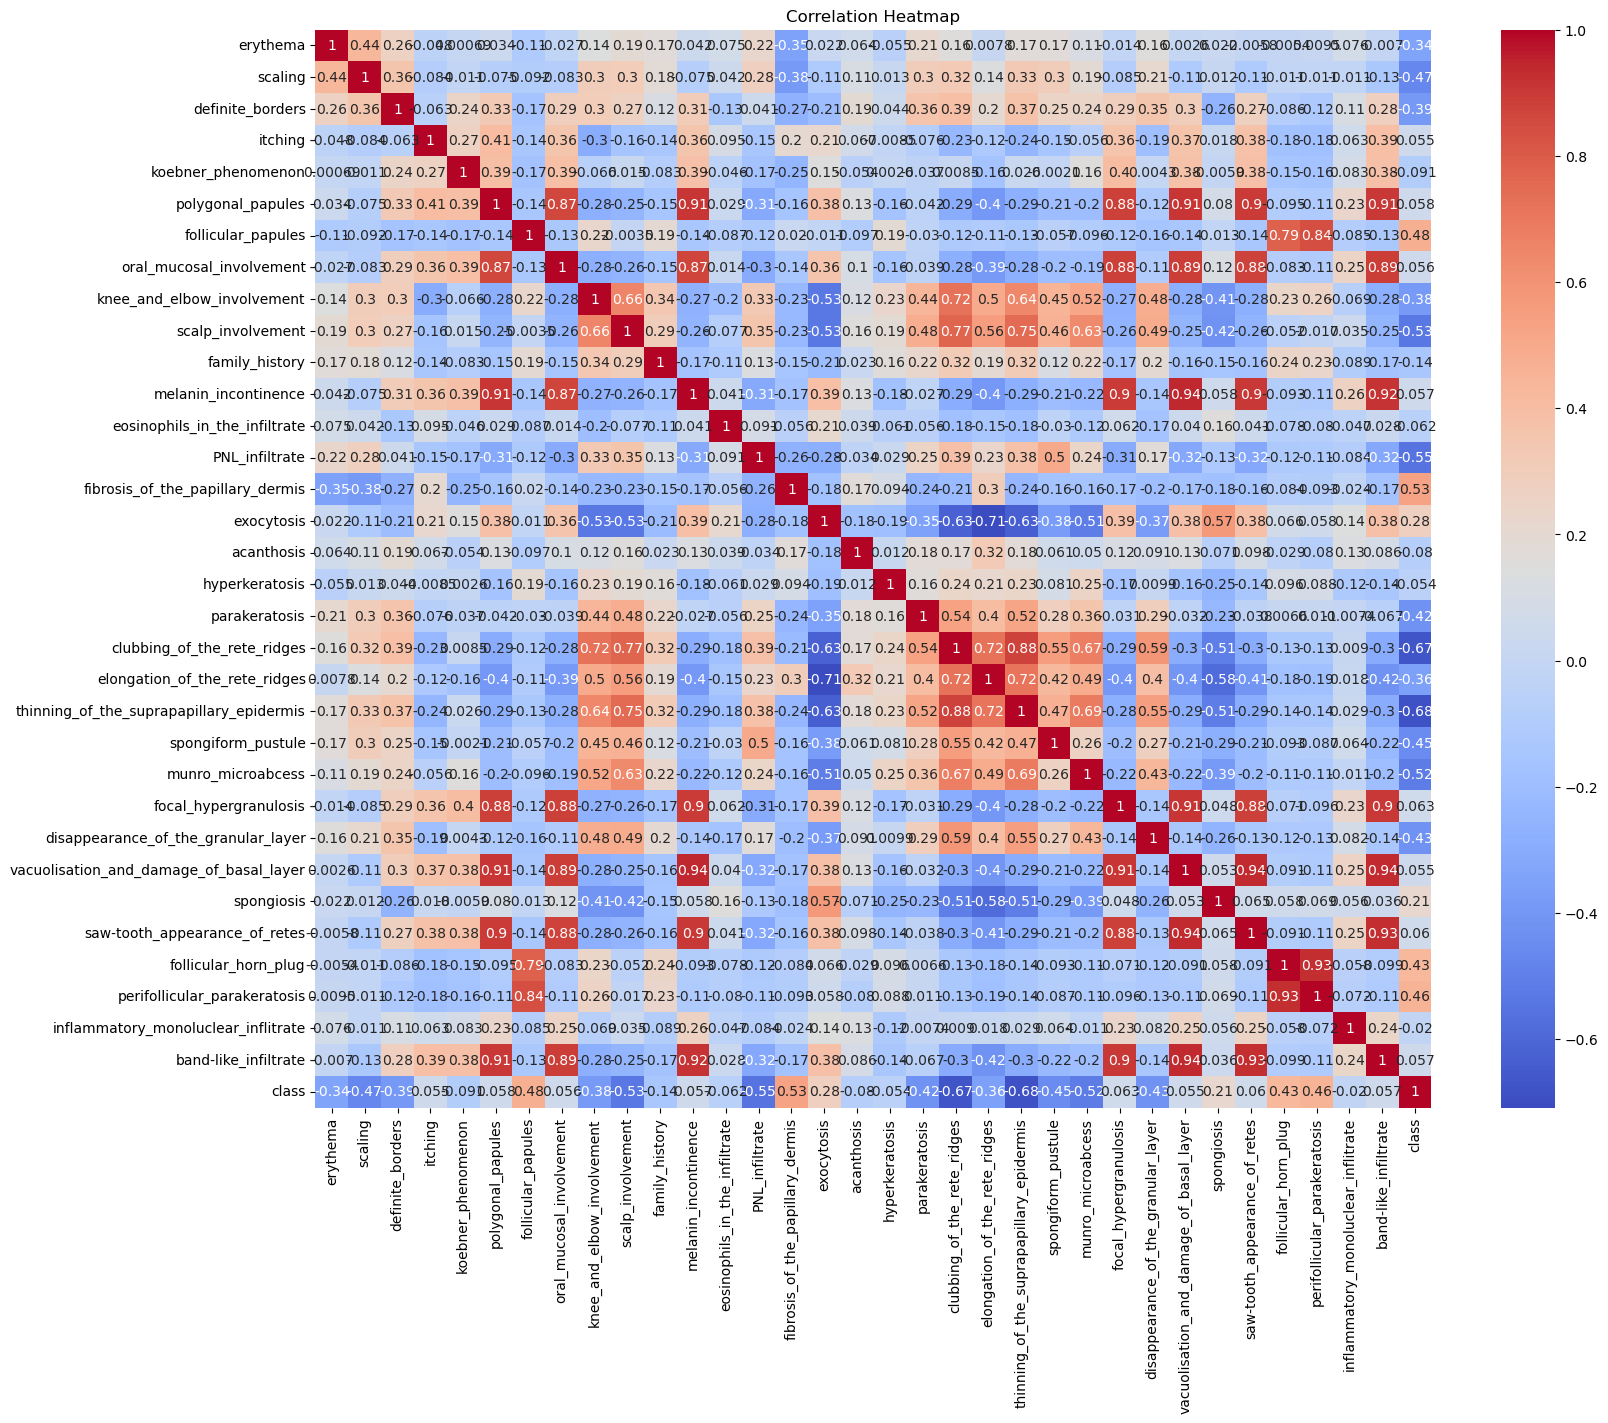

In [30]:
plt.figure(figsize=(18,14))  # Set figure size
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")  # Show feature correlations
plt.title("Correlation Heatmap")  # Set plot title
plt.show()  # Display heatmap

### Insight: 
* Shows correlations between numerical features to identify relationships and highly correlated features.

# Feature Engineering


### 1) DATA PREPROCESSING

In [31]:
for col in df.columns:  # Loop through all columns
    print(col, ":", sorted(df[col].unique()))  # Print sorted unique values

erythema : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
scaling : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
definite_borders : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
itching : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
koebner_phenomenon : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
polygonal_papules : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
follicular_papules : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
oral_mucosal_involvement : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
knee_and_elbow_involvement : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
scalp_involvement : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
family_history : [np.int64(0), np.int64(1)]
melanin_incontinence : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
eosinophils_in_the_infiltrate : [np.int64(0), np.int64(1), np.int64(2)]
PNL_infiltrate : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
fibrosis_of_the_papi

In [32]:
df.dtypes  # Display data types of all columns

erythema                                     int64
scaling                                      int64
definite_borders                             int64
itching                                      int64
koebner_phenomenon                           int64
polygonal_papules                            int64
follicular_papules                           int64
oral_mucosal_involvement                     int64
knee_and_elbow_involvement                   int64
scalp_involvement                            int64
family_history                               int64
melanin_incontinence                         int64
eosinophils_in_the_infiltrate                int64
PNL_infiltrate                               int64
fibrosis_of_the_papillary_dermis             int64
exocytosis                                   int64
acanthosis                                   int64
hyperkeratosis                               int64
parakeratosis                                int64
clubbing_of_the_rete_ridges    

In [33]:
df.loc[df["Age"]=="?","Age"]# finding invalid value using .loc

33     ?
34     ?
35     ?
36     ?
262    ?
263    ?
264    ?
265    ?
Name: Age, dtype: object

In [34]:
df.Age.value_counts() #checking how many time value repeated

Age
40    17
50    17
27    16
36    16
22    15
      ..
58     1
49     1
63     1
68     1
75     1
Name: count, Length: 61, dtype: int64

In [35]:
df.loc[df["Age"]=="?","Age"]=36 # using median replace valid value 

In [36]:
df.Age = df.Age.astype(int)  # change datatype 

In [37]:
df.Age.dtype  # Check the data type of the Age column

dtype('int64')

In [38]:
df.loc[df["Age"] < 11]  # Display rows where age is below 11

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,family_history,melanin_incontinence,eosinophils_in_the_infiltrate,PNL_infiltrate,fibrosis_of_the_papillary_dermis,exocytosis,acanthosis,hyperkeratosis,parakeratosis,clubbing_of_the_rete_ridges,elongation_of_the_rete_ridges,thinning_of_the_suprapapillary_epidermis,spongiform_pustule,munro_microabcess,focal_hypergranulosis,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age,class
1,3,3,3,2,1,0,0,0,1,1,1,0,0,1,0,1,2,0,2,2,2,2,2,1,0,0,0,0,0,0,0,1,0,8,1
13,2,3,3,0,0,0,0,0,1,1,1,0,0,1,0,0,2,1,2,1,2,3,0,2,0,0,0,0,0,0,0,2,0,10,1
20,2,1,1,2,0,0,3,0,1,2,0,0,0,1,0,0,1,2,2,0,1,0,1,0,0,0,0,0,0,1,2,1,0,8,6
26,1,1,0,1,0,0,3,0,1,0,0,0,0,1,0,0,1,1,1,0,0,0,0,0,1,0,0,1,0,2,2,1,0,10,6
31,3,2,0,2,0,0,0,0,0,0,0,0,1,2,0,2,1,1,1,0,0,0,1,0,0,0,0,0,0,0,0,1,0,10,2
60,2,2,1,1,0,0,1,0,1,1,1,0,0,0,0,1,2,1,1,1,1,0,0,0,0,0,0,1,0,1,1,1,0,8,6
83,3,2,2,1,0,0,0,0,0,0,0,0,0,1,0,2,1,0,2,0,0,0,0,0,0,0,0,2,0,0,0,2,0,10,2
119,1,1,1,1,1,0,0,0,2,2,0,0,0,2,0,0,2,1,1,2,2,1,0,2,0,0,0,0,0,0,0,0,2,0,1
122,1,1,2,0,0,0,3,0,3,0,1,0,0,0,0,2,1,1,1,1,0,0,0,0,0,0,0,0,0,2,2,2,0,7,6
126,2,2,2,0,0,0,2,0,2,0,0,0,0,0,0,2,2,2,2,0,0,0,0,0,0,0,0,0,0,2,2,2,0,8,6


In [39]:
X = df.drop("class", axis=1)  # Select input features
y = df["class"]  # Select target variable

In [40]:
id_columns = ["id", "patient_id"]  # Define ID columns

for col in id_columns:  # Check each ID column
    if col in df.columns:  # Check if column exists
        print(col)  # Print column name

In [41]:
duplicate_columns = []  # Store duplicate columns

for i in range(len(df.columns)):  # Loop through columns
    for j in range(i + 1, len(df.columns)):  # Compare column pairs
        if df[df.columns[i]].equals(df[df.columns[j]]):  # Check identical values
            duplicate_columns.append((df.columns[i], df.columns[j]))  # Store duplicate pair

duplicate_columns  # Display duplicate columns

[]

In [42]:
constant_features = [col for col in df.columns if df[col].nunique() <= 1]  # Find columns with only one unique value

constant_features  # Display constant features

[]

In [43]:
df.isnull().sum().sum()  # Count total missing values in the dataset

np.int64(0)

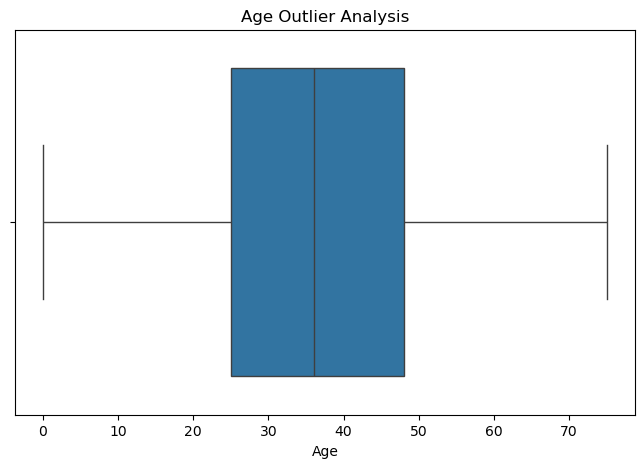

In [44]:
plt.figure(figsize=(8,5))  # Set figure size
sns.boxplot(x=df["Age"])  # Identify potential age outliers
plt.title("Age Outlier Analysis")  # Set plot title
plt.show()  # Display boxplot

### Insight: 
* Identifies potential outliers in the Age column by showing the median, spread, and unusually low or high age values.

In [45]:
print("X shape:", X.shape)  # Display input features dimensions
print("y shape:", y.shape)  # Display target variable dimensions

X shape: (366, 34)
y shape: (366,)


In [46]:
X.head()  # Display the first five rows of input features

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,family_history,melanin_incontinence,eosinophils_in_the_infiltrate,PNL_infiltrate,fibrosis_of_the_papillary_dermis,exocytosis,acanthosis,hyperkeratosis,parakeratosis,clubbing_of_the_rete_ridges,elongation_of_the_rete_ridges,thinning_of_the_suprapapillary_epidermis,spongiform_pustule,munro_microabcess,focal_hypergranulosis,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age
0,2,2,0,3,0,0,0,0,1,0,0,0,0,0,0,3,2,0,0,0,0,0,0,0,0,0,0,3,0,0,0,1,0,55
1,3,3,3,2,1,0,0,0,1,1,1,0,0,1,0,1,2,0,2,2,2,2,2,1,0,0,0,0,0,0,0,1,0,8
2,2,1,2,3,1,3,0,3,0,0,0,1,0,0,0,1,2,0,2,0,0,0,0,0,2,0,2,3,2,0,0,2,3,26
3,2,2,2,0,0,0,0,0,3,2,0,0,0,3,0,0,2,0,3,2,2,2,2,0,0,3,0,0,0,0,0,3,0,40
4,2,3,2,2,2,2,0,2,0,0,0,1,0,0,0,1,2,0,0,0,0,0,0,0,2,2,3,2,3,0,0,2,3,45


In [47]:
y.head()  # Display the first five target values

0    2
1    1
2    3
3    1
4    3
Name: class, dtype: int64

### 2) Train-Test Split 

In [48]:
from sklearn.model_selection import train_test_split  # Import function to split data into training and testing sets

In [49]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)  # Split data into 80% training and 20% testing sets

In [50]:
print("X_train:", X_train.shape)  # Display training features shape
print("X_test :", X_test.shape)  # Display testing features shape
print("y_train:", y_train.shape)  # Display training target shape
print("y_test :", y_test.shape)  # Display testing target shape

X_train: (292, 34)
X_test : (74, 34)
y_train: (292,)
y_test : (74,)


In [51]:
print(y_train.value_counts().sort_index())  # Count samples in each training class
print(y_train.value_counts(normalize=True).sort_index() * 100)  # Display class percentages

class
1    89
2    49
3    57
4    39
5    42
6    16
Name: count, dtype: int64
class
1    30.479452
2    16.780822
3    19.520548
4    13.356164
5    14.383562
6     5.479452
Name: proportion, dtype: float64


In [52]:
print(y_test.value_counts().sort_index())  # Count samples in each testing class
print(y_test.value_counts(normalize=True).sort_index() * 100)  # Display class percentages

class
1    23
2    12
3    15
4    10
5    10
6     4
Name: count, dtype: int64
class
1    31.081081
2    16.216216
3    20.270270
4    13.513514
5    13.513514
6     5.405405
Name: proportion, dtype: float64


### 3) Converting Balancing Data

In [53]:
from imblearn.over_sampling import SMOTE  # Import SMOTE to balance class distribution

In [54]:
smote = SMOTE(random_state=42)  # Initialize SMOTE

X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)  # Balance training data

In [55]:
print("Before SMOTE:")  # Display heading
print(y_train.value_counts().sort_index())  # Show class counts before SMOTE

Before SMOTE:
class
1    89
2    49
3    57
4    39
5    42
6    16
Name: count, dtype: int64


In [56]:
print("After SMOTE:")  # Display heading
print(y_train_smote.value_counts().sort_index())  # Show class counts after SMOTE

After SMOTE:
class
1    89
2    89
3    89
4    89
5    89
6    89
Name: count, dtype: int64


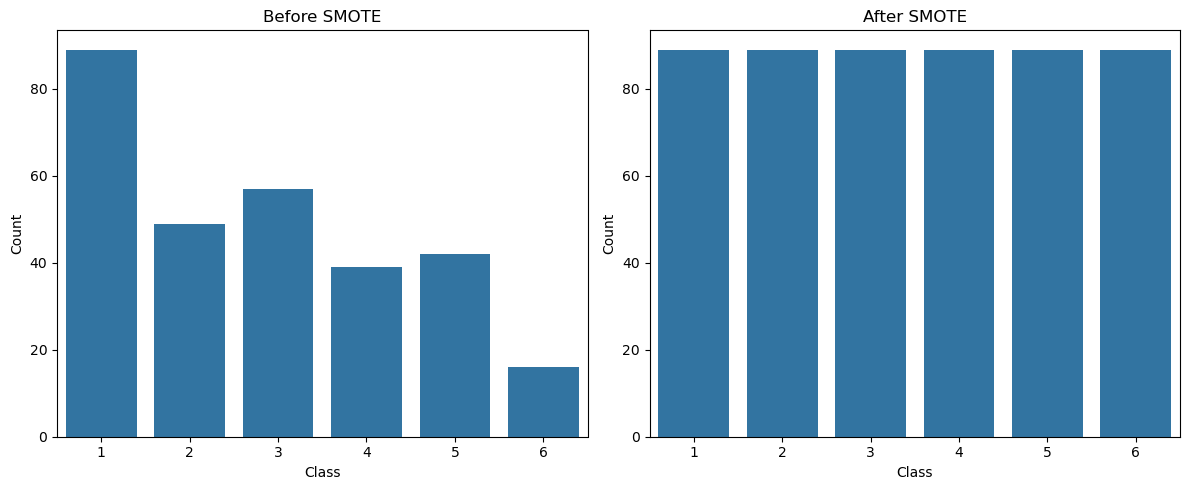

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(12,5))  # Create two side-by-side plots

sns.countplot(x=y_train, ax=axes[0])  # Plot class counts before SMOTE
axes[0].set_title("Before SMOTE")  # Set first plot title
axes[0].set_xlabel("Class")  # Label x-axis
axes[0].set_ylabel("Count")  # Label y-axis

sns.countplot(x=y_train_smote, ax=axes[1])  # Plot class counts after SMOTE
axes[1].set_title("After SMOTE")  # Set second plot title
axes[1].set_xlabel("Class")  # Label x-axis
axes[1].set_ylabel("Count")  # Label y-axis

plt.tight_layout()  # Adjust plot spacing
plt.show()  # Display both plots

### Insight: 
* SMOTE balances the training dataset by increasing minority-class samples, helping reduce class imbalance.

### 4) Standardization of Features using StandardScaler

In [58]:
from sklearn.preprocessing import StandardScaler  # Import feature scaling tool

scaler = StandardScaler()  # Initialize the scaler

In [59]:
X_train_scaled = scaler.fit_transform(X_train_smote)  # Fit scaler and standardize training data
X_test_scaled = scaler.transform(X_test)  # Standardize testing data using the same scaler

In [60]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)  # Convert scaled training data into DataFrame

X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)  # Convert scaled testing data into DataFrame

In [61]:
print("Training data shape:", X_train_scaled.shape)  # Display scaled training data dimensions
print("Testing data shape :", X_test_scaled.shape)  # Display scaled testing data dimensions
print("Training target shape:", y_train_smote.shape)  # Display training target dimensions
print("Testing target shape :", y_test.shape)  # Display testing target dimensions

Training data shape: (534, 34)
Testing data shape : (74, 34)
Training target shape: (534,)
Testing target shape : (74,)


### 5) Feature Selection

In [62]:
constant_features = [col for col in X_train_smote.columns if X_train_smote[col].nunique() <= 1]  # Find constant features

print("Constant Features:", constant_features)  # Display constant features

Constant Features: []


In [63]:
X_train_smote = X_train_smote.drop(columns=constant_features)  # Remove constant features from training data
X_test_scaled = X_test_scaled.drop(columns=constant_features)  # Remove constant features from testing data

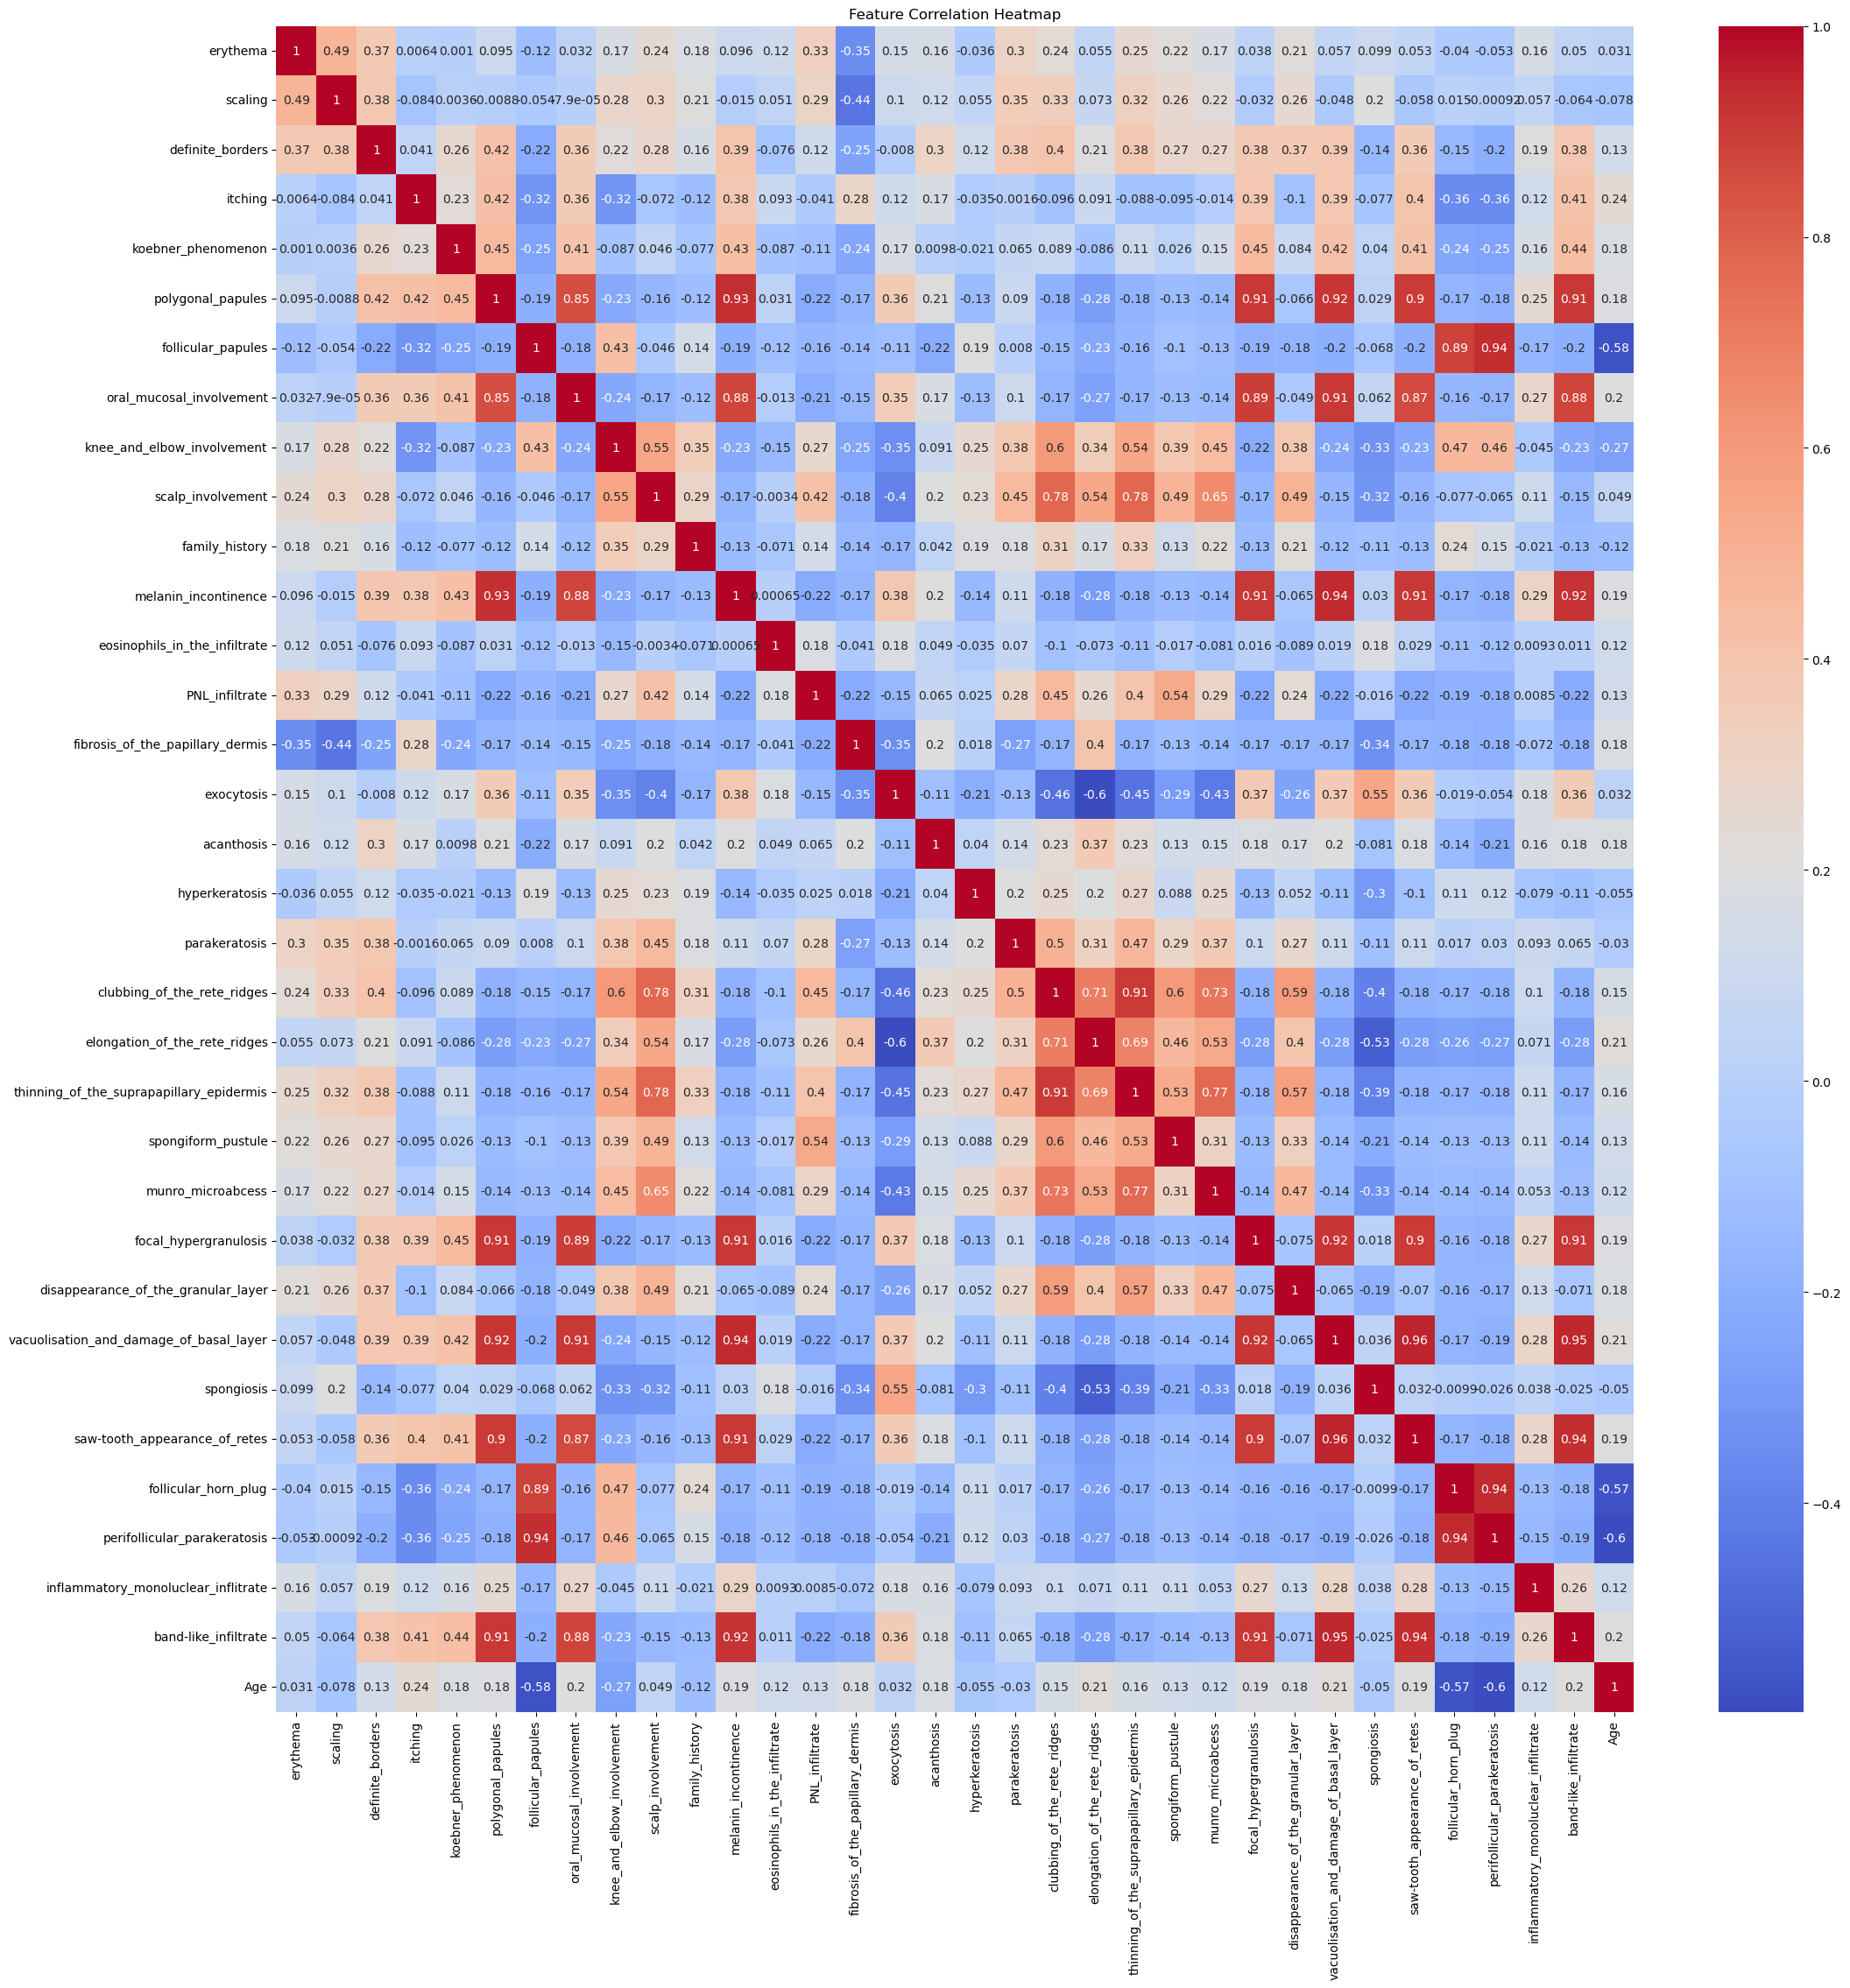

In [64]:
plt.figure(figsize=(25,25))  # Set figure size
sns.heatmap(X_train_smote.corr(), annot=True, cmap="coolwarm")  # Plot feature correlations
plt.title("Feature Correlation Heatmap")  # Set plot title
plt.show()  # Display heatmap

### Insight: 
* Identifies highly correlated features in the training data to help detect redundant features.

In [65]:
corr_matrix = X_train_smote.corr().abs()  # Calculate absolute correlation values

upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))  # Select upper triangle

high_corr = [column for column in upper.columns if any(upper[column] > 0.90)]  # Find features correlated above 90%

print("Highly Correlated Features:")  # Display heading
print(high_corr)  # Print highly correlated features

Highly Correlated Features:
['melanin_incontinence', 'thinning_of_the_suprapapillary_epidermis', 'focal_hypergranulosis', 'vacuolisation_and_damage_of_basal_layer', 'saw-tooth_appearance_of_retes', 'perifollicular_parakeratosis', 'band-like_infiltrate']


In [66]:
from sklearn.feature_selection import SelectKBest, mutual_info_classif  # Import feature selection tools

selector = SelectKBest(score_func=mutual_info_classif, k="all")  # Initialize feature selector

selector.fit(X_train_smote, y_train_smote)  # Calculate feature importance scores

SelectKBest(k='all',
            score_func=<function mutual_info_classif at 0x00000254A4A4DB20>)

In [67]:
feature_scores = pd.DataFrame({  # Create feature score DataFrame
    "Feature": X_train_smote.columns,  # Store feature names
    "Score": selector.scores_  # Store feature importance scores
})

feature_scores = feature_scores.sort_values(by="Score", ascending=False)  # Sort scores in descending order

feature_scores  # Display feature scores

,Feature,Score
33,Age,0.544179
20,elongation_of_the_rete_ridges,0.520486
30,perifollicular_parakeratosis,0.498729
26,vacuolisation_and_damage_of_basal_layer,0.494359
8,knee_and_elbow_involvement,0.490272
29,follicular_horn_plug,0.479222
24,focal_hypergranulosis,0.471573
27,spongiosis,0.465902
14,fibrosis_of_the_papillary_dermis,0.451146
11,melanin_incontinence,0.444615


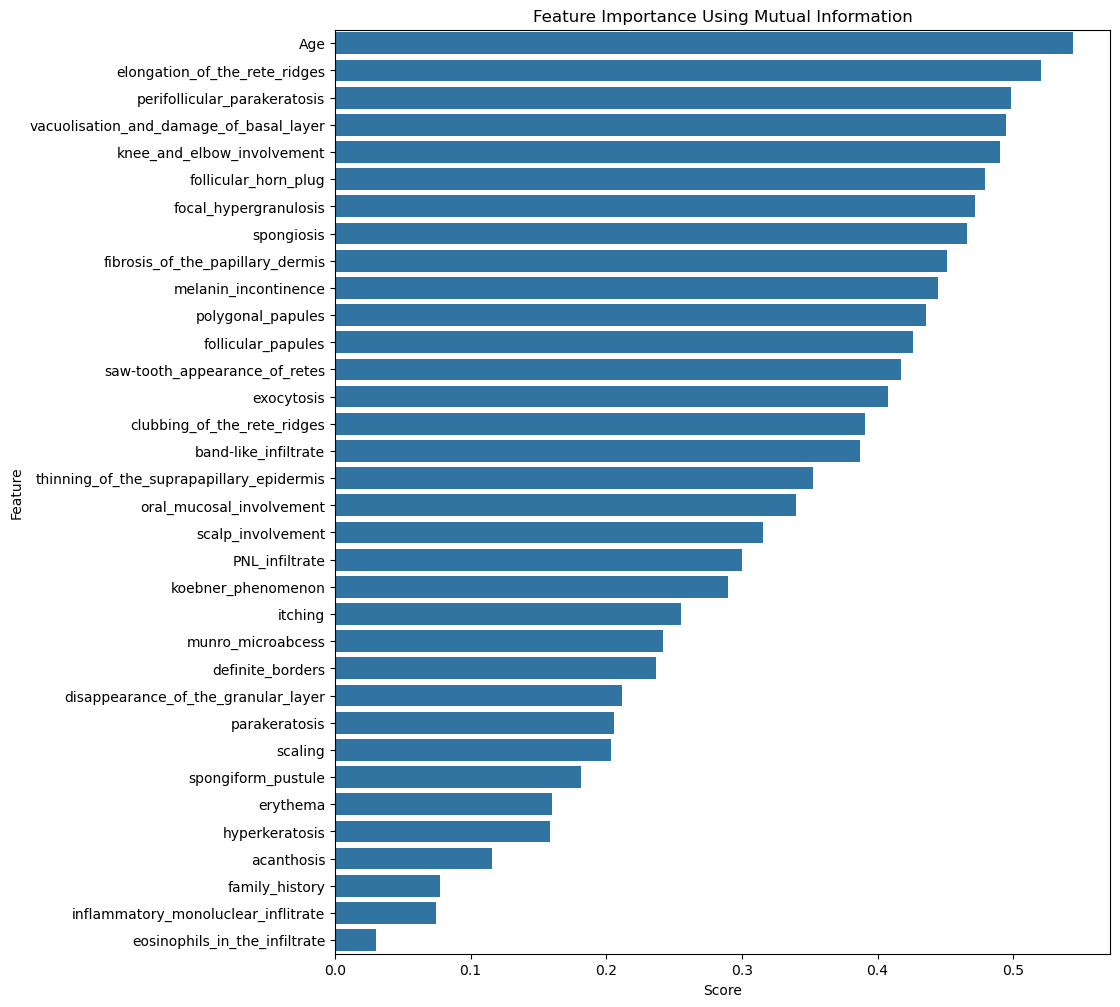

In [68]:
plt.figure(figsize=(10,12))  # Set figure size
sns.barplot(data=feature_scores, x="Score", y="Feature")  # Plot feature scores
plt.title("Feature Importance Using Mutual Information")  # Set plot title
plt.show()  # Display graph

In [69]:
top_features = feature_scores.head(20)["Feature"].tolist()  # Select top 20 features

print("Top Features:")  # Display heading
print(top_features)  # Print selected features

Top Features:
['Age', 'elongation_of_the_rete_ridges', 'perifollicular_parakeratosis', 'vacuolisation_and_damage_of_basal_layer', 'knee_and_elbow_involvement', 'follicular_horn_plug', 'focal_hypergranulosis', 'spongiosis', 'fibrosis_of_the_papillary_dermis', 'melanin_incontinence', 'polygonal_papules', 'follicular_papules', 'saw-tooth_appearance_of_retes', 'exocytosis', 'clubbing_of_the_rete_ridges', 'band-like_infiltrate', 'thinning_of_the_suprapapillary_epidermis', 'oral_mucosal_involvement', 'scalp_involvement', 'PNL_infiltrate']


In [70]:
X_train_selected = X_train_smote[top_features]  # Select top features from training data
X_test_selected = X_test_scaled[top_features]  # Select top features from testing data

print("Selected Training Shape:", X_train_selected.shape)  # Display training shape
print("Selected Testing Shape :", X_test_selected.shape)  # Display testing shape

Selected Training Shape: (534, 20)
Selected Testing Shape : (74, 20)


# Model Selection

### Logistic Regression

In [71]:
from sklearn.linear_model import LogisticRegression  # Import Logistic Regression model

In [72]:
lr_model = LogisticRegression()  # Initialize Logistic Regression model

In [73]:
lr_model.fit(X_train_selected, y_train_smote)  # Train Logistic Regression model
print("Logistic Regression Model Created Successfully")  # Display success message

Logistic Regression Model Created Successfully


In [74]:
y_pred_lr = lr_model.predict(X_test_selected)  # Predict skin disorder classes for test data
y_pred_lr  # Display predicted results

array([4, 3, 4, 1, 4, 3, 4, 1, 4, 3, 1, 5, 5, 3, 5, 6, 6, 1, 5, 3, 1, 4,
       1, 1, 4, 3, 4, 1, 6, 2, 4, 5, 2, 4, 3, 1, 3, 5, 1, 1, 4, 1, 4, 1,
       1, 4, 1, 1, 3, 5, 1, 1, 1, 4, 3, 3, 1, 6, 4, 1, 1, 3, 5, 5, 2, 3,
       3, 4, 1, 3, 2, 4, 4, 5])

### Model Evulation 

In [75]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report  # Import classification evaluation metrics

In [76]:
lr_accuracy = accuracy_score(y_test, y_pred_lr)  # Calculate Logistic Regression accuracy

In [77]:
lr_precision = precision_score(y_test, y_pred_lr, average="weighted")  # Calculate weighted precision

In [78]:
lr_recall = recall_score(y_test, y_pred_lr, average="weighted")  # Calculate weighted recall

In [79]:
lr_f1 = f1_score(y_test, y_pred_lr, average="weighted")  # Calculate weighted F1-score

In [80]:
print("Logistic Regression Model Evaluation Results")  # Display evaluation heading
print("-----------------")  # Print separator
print("Accuracy :", lr_accuracy)  # Display accuracy
print("Precision:", lr_precision)  # Display precision
print("Recall   :", lr_recall)  # Display recall
print("F1 Score :", lr_f1)  # Display F1-score

Logistic Regression Model Evaluation Results
-----------------
Accuracy : 0.8918918918918919
Precision: 0.93993993993994
Recall   : 0.8918918918918919
F1 Score : 0.8803088803088802


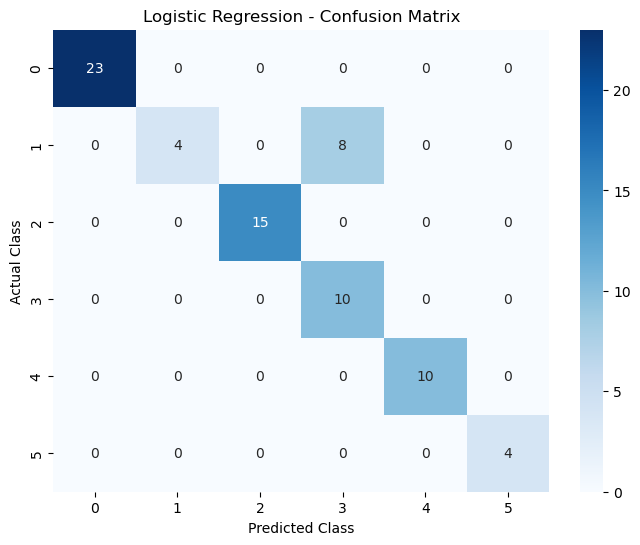

In [81]:
cm_lr = confusion_matrix(y_test, y_pred_lr)  # Create confusion matrix
cm_lr  # Display confusion matrix values

plt.figure(figsize=(8, 6))  # Set figure size

sns.heatmap(
    cm_lr,  # Provide confusion matrix data
    annot=True,  # Display values inside cells
    fmt="d",  # Show values as integers
    cmap="Blues"  # Set blue color palette
)

plt.title("Logistic Regression - Confusion Matrix")  # Add chart title
plt.xlabel("Predicted Class")  # Label x-axis
plt.ylabel("Actual Class")  # Label y-axis

plt.show()  # Display confusion matrix heatmap

### Hyper Parameter Tunning with Logistic Regression

In [85]:
from sklearn.model_selection import GridSearchCV  # Import GridSearchCV for hyperparameter tuning

In [86]:
lr_param_grid = {  # Define hyperparameter values for tuning
    "C": [0.01, 0.1, 1, 10, 100],  # Set regularization strength values
    "solver": ["lbfgs", "liblinear"]  # Set optimization algorithms
}

In [87]:
lr_grid = GridSearchCV(
    estimator=LogisticRegression(max_iter=2000, random_state=42),  # Set Logistic Regression model
    param_grid=lr_param_grid,  # Provide hyperparameter combinations
    cv=5,  # Use 5-fold cross-validation
    scoring="f1_weighted",  # Evaluate using weighted F1-score
    n_jobs=-1  # Use all available CPU cores
)
lr_grid  # Display GridSearchCV configuration

GridSearchCV(cv=5, estimator=LogisticRegression(max_iter=2000, random_state=42),
             n_jobs=-1,
             param_grid={'C': [0.01, 0.1, 1, 10, 100],
                         'solver': ['lbfgs', 'liblinear']},
             scoring='f1_weighted')

In [88]:
lr_grid.fit(X_train_selected, y_train_smote)  # Perform hyperparameter tuning using GridSearchCV
print("Logistic Regression Hyperparameter Tuning Completed")  # Display completion message

Logistic Regression Hyperparameter Tuning Completed


In [89]:
print("Best Parameters:")  # Display best hyperparameters
print(lr_grid.best_params_)  # Show the best parameter combination

print("Best Cross Validation F1 Score:")  # Display best cross-validation score
print(lr_grid.best_score_)  # Show the best weighted F1-score

Best Parameters:
{'C': 0.1, 'solver': 'liblinear'}
Best Cross Validation F1 Score:
0.9348416071268584


In [90]:
lr_tuned = lr_grid.best_estimator_  # Select the best-tuned Logistic Regression model
lr_tuned  # Display the tuned model

LogisticRegression(C=0.1, max_iter=2000, random_state=42, solver='liblinear')

In [91]:
y_pred_lr_tuned = lr_tuned.predict(X_test_selected)  # Predict classes using the tuned model
y_pred_lr_tuned  # Display tuned predictions

array([2, 3, 4, 1, 4, 3, 4, 1, 4, 3, 1, 5, 5, 3, 5, 6, 6, 1, 5, 3, 1, 4,
       1, 1, 2, 3, 2, 1, 6, 2, 4, 5, 2, 2, 3, 1, 3, 5, 1, 1, 2, 1, 4, 1,
       1, 4, 1, 1, 3, 5, 1, 1, 1, 2, 3, 3, 1, 6, 4, 1, 1, 3, 5, 5, 2, 3,
       3, 4, 1, 3, 2, 4, 2, 5])

### Logistic Regression in Model Evulation with Hyper Parameter Tunning"

In [92]:
lr_tuned_accuracy = accuracy_score(y_test, y_pred_lr_tuned)  # Calculate tuned model accuracy

In [93]:
lr_tuned_precision = precision_score(y_test, y_pred_lr_tuned, average="weighted")  # Calculate tuned model precision

In [94]:
lr_tuned_recall = recall_score(y_test, y_pred_lr_tuned, average="weighted")  # Calculate tuned model recall

In [95]:
lr_tuned_f1 = f1_score(y_test, y_pred_lr_tuned, average="weighted")  # Calculate tuned model F1-score

In [96]:
print("Logistic Regression Model Evaluation with Hyperparameter Tuning Results")  # Display evaluation heading
print("-----------------")  # Print separator
print("Accuracy :", lr_tuned_accuracy)  # Display tuned accuracy
print("Precision:", lr_tuned_precision)  # Display tuned precision
print("Recall   :", lr_tuned_recall)  # Display tuned recall
print("F1 Score :", lr_tuned_f1)  # Display tuned F1-score

Logistic Regression Model Evaluation with Hyperparameter Tuning Results
-----------------
Accuracy : 0.9324324324324325
Precision: 0.9336609336609337
Recall   : 0.9324324324324325
F1 Score : 0.9325723238766718


In [97]:
Lr_tuned_CR = classification_report(y_test, y_pred_lr_tuned)  # Generate tuned model classification report
print(Lr_tuned_CR)  # Display precision, recall, F1-score, and support for each class

              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       0.82      0.75      0.78        12
           3       1.00      1.00      1.00        15
           4       0.73      0.80      0.76        10
           5       1.00      1.00      1.00        10
           6       1.00      1.00      1.00         4

    accuracy                           0.93        74
   macro avg       0.92      0.92      0.92        74
weighted avg       0.93      0.93      0.93        74



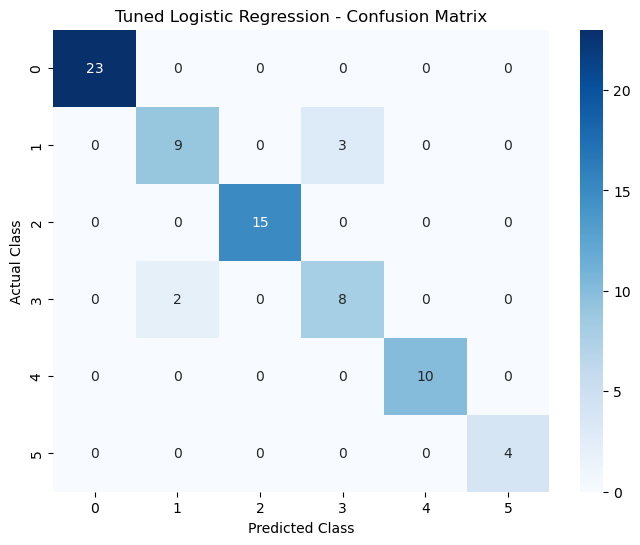

In [98]:
cm_lr_tuned = confusion_matrix(y_test, y_pred_lr_tuned)  # Create tuned model confusion matrix
plt.figure(figsize=(8, 6))  # Set figure size
sns.heatmap(cm_lr_tuned, annot=True, fmt="d", cmap="Blues")  # Plot confusion matrix heatmap
plt.title("Tuned Logistic Regression - Confusion Matrix")  # Add chart title
plt.xlabel("Predicted Class")  # Label x-axis
plt.ylabel("Actual Class")  # Label y-axis
plt.show()  # Display confusion matrix

### KNN

In [99]:
from sklearn.neighbors import KNeighborsClassifier  # Import KNN classification algorithm

In [100]:
knn_model = KNeighborsClassifier()  # Initialize KNN model

In [101]:
knn_model.fit(X_train_selected, y_train_smote)  # Train KNN model
print("KNN Model Created Successfully")  # Display success message

KNN Model Created Successfully


In [102]:
y_pred_knn = knn_model.predict(X_test_selected)  # Predict skin disorder classes using KNN
y_pred_knn  # Display predicted results

array([6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 1, 6, 6, 1, 6,
       1, 1, 6, 6, 6, 1, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 1, 1, 6, 1, 6, 1,
       1, 6, 1, 1, 6, 6, 1, 6, 1, 6, 6, 6, 6, 6, 6, 6, 1, 6, 6, 6, 6, 6,
       6, 6, 6, 6, 6, 6, 6, 6])

### Model Evaluation

In [103]:
knn_accuracy = accuracy_score(y_test, y_pred_knn)  # Calculate KNN model accuracy

In [104]:
knn_precision = precision_score(y_test, y_pred_knn, average="weighted")  # Calculate weighted KNN precision

In [105]:
knn_recall = recall_score(y_test, y_pred_knn, average="weighted")  # Calculate weighted KNN recall

In [106]:
knn_f1 = f1_score(y_test, y_pred_knn, average="weighted")  # Calculate weighted KNN F1-score

In [107]:
print("KNN Model Evaluation Results")  # Display evaluation heading
print("-----------------")  # Print separator
print("Accuracy :", knn_accuracy)  # Display accuracy
print("Precision:", knn_precision)  # Display precision
print("Recall   :", knn_recall)  # Display recall
print("F1 Score :", knn_f1)  # Display F1-score

KNN Model Evaluation Results
-----------------
Accuracy : 0.25675675675675674
Precision: 0.3144754924415941
Recall   : 0.25675675675675674
F1 Score : 0.2522409627672786


In [108]:
knn_cr = classification_report(y_test, y_pred_knn)  # Generate KNN classification report
print(knn_cr)  # Display precision, recall, F1-score, and support for each class

              precision    recall  f1-score   support

           1       1.00      0.65      0.79        23
           2       0.00      0.00      0.00        12
           3       0.00      0.00      0.00        15
           4       0.00      0.00      0.00        10
           5       0.00      0.00      0.00        10
           6       0.07      1.00      0.13         4

    accuracy                           0.26        74
   macro avg       0.18      0.28      0.15        74
weighted avg       0.31      0.26      0.25        74



### KNN with Hyperparameter Tuning

In [109]:
knn_param_grid = {  # Define KNN hyperparameter values
    "n_neighbors": [3, 5, 7, 9, 11],  # Set the number of neighbors
    "weights": ["uniform", "distance"],  # Set neighbor weighting methods
    "metric": ["euclidean", "manhattan"]  # Set distance calculation methods
}
knn_param_grid  # Display parameter grid

{'n_neighbors': [3, 5, 7, 9, 11],
 'weights': ['uniform', 'distance'],
 'metric': ['euclidean', 'manhattan']}

In [110]:
knn_grid = GridSearchCV(
    estimator=KNeighborsClassifier(),  # Set KNN model
    param_grid=knn_param_grid,  # Provide hyperparameter combinations
    cv=5,  # Use 5-fold cross-validation
    scoring="f1_weighted",  # Evaluate using weighted F1-score
    n_jobs=-1  # Use all available CPU cores
)
knn_grid  # Display GridSearchCV configuration

GridSearchCV(cv=5, estimator=KNeighborsClassifier(), n_jobs=-1,
             param_grid={'metric': ['euclidean', 'manhattan'],
                         'n_neighbors': [3, 5, 7, 9, 11],
                         'weights': ['uniform', 'distance']},
             scoring='f1_weighted')

In [111]:
knn_grid.fit(X_train_selected, y_train_smote)  # Perform KNN hyperparameter tuning
print("KNN Hyperparameter Tuning Completed")  # Display completion message

KNN Hyperparameter Tuning Completed


In [112]:
print("Best Parameters:")  # Display best hyperparameters
print(knn_grid.best_params_)  # Show the best parameter combination

print("Best Cross Validation F1 Score:")  # Display best cross-validation score
print(knn_grid.best_score_)  # Show the best weighted F1-score

Best Parameters:
{'metric': 'manhattan', 'n_neighbors': 5, 'weights': 'distance'}
Best Cross Validation F1 Score:
0.9364359093335212


In [113]:
knn_tuned = knn_grid.best_estimator_  # Select the best-tuned KNN model
knn_tuned  # Display the tuned model

KNeighborsClassifier(metric='manhattan', weights='distance')

In [114]:
y_pred_knn_tuned = knn_tuned.predict(X_test_selected)  # Predict classes using the tuned KNN model
y_pred_knn_tuned  # Display tuned KNN predictions

array([6, 3, 6, 1, 6, 3, 6, 1, 6, 3, 1, 6, 6, 3, 6, 6, 6, 1, 6, 3, 1, 6,
       1, 1, 6, 6, 6, 1, 6, 6, 6, 6, 6, 2, 3, 1, 6, 6, 1, 1, 6, 1, 6, 1,
       1, 6, 1, 1, 6, 6, 1, 1, 1, 6, 3, 6, 1, 6, 6, 1, 1, 3, 6, 6, 2, 6,
       3, 6, 1, 3, 6, 6, 6, 6])

### Model Evulation

In [115]:
knn_tuned_accuracy = accuracy_score(y_test, y_pred_knn_tuned)  # Calculate tuned KNN model accuracy

In [116]:
knn_tuned_precision = precision_score(y_test, y_pred_knn_tuned, average="weighted")# Calculate weighted precision for the tuned KNN model

In [117]:
knn_tuned_recall = recall_score(y_test, y_pred_knn_tuned, average="weighted")  # Calculate weighted recall for the tuned KNN model

In [118]:
knn_tuned_f1 = f1_score(y_test, y_pred_knn_tuned, average="weighted")# Calculate weighted F1-score for the tuned KNN model

In [119]:
print("KNN Model Evaluation with Hyperparameter Tuning Results")  # Display evaluation heading
print("-----------------")  # Print separator
print("Accuracy :", knn_tuned_accuracy)  # Display tuned accuracy
print("Precision:", knn_tuned_precision)  # Display tuned precision
print("Recall   :", knn_tuned_recall)  # Display tuned recall
print("F1 Score :", knn_tuned_f1)  # Display tuned F1-score

KNN Model Evaluation with Hyperparameter Tuning Results
-----------------
Accuracy : 0.527027027027027
Precision: 0.6812196812196812
Recall   : 0.527027027027027
F1 Score : 0.5293615875011224


In [120]:
knn_tunned_CR = classification_report(y_test, y_pred_knn_tuned)# Generate classification report for the tuned KNN model
print(knn_tunned_CR)  # Display precision, recall, F1-score, and support for each class

              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       1.00      0.17      0.29        12
           3       1.00      0.67      0.80        15
           4       0.00      0.00      0.00        10
           5       0.00      0.00      0.00        10
           6       0.10      1.00      0.19         4

    accuracy                           0.53        74
   macro avg       0.52      0.47      0.38        74
weighted avg       0.68      0.53      0.53        74



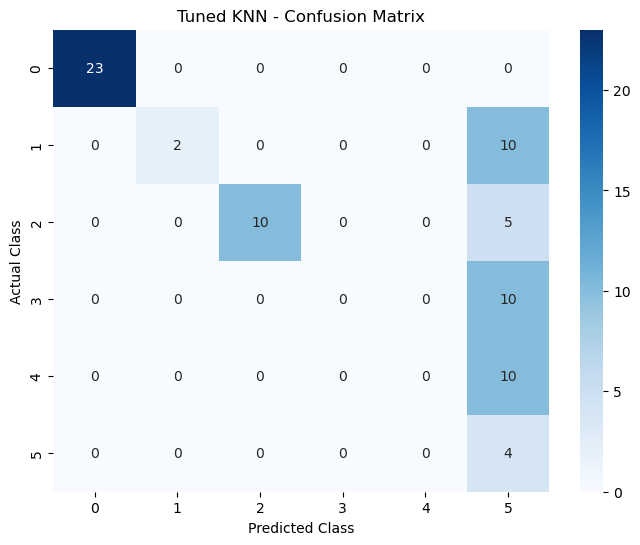

In [121]:
cm_knn = confusion_matrix(y_test, y_pred_knn_tuned)  # Create confusion matrix for tuned KNN model

plt.figure(figsize=(8, 6))  # Set figure size

sns.heatmap(cm_knn, annot=True, fmt="d", cmap="Blues")  # Display confusion matrix as a heatmap
plt.title("Tuned KNN - Confusion Matrix")  # Add chart title
plt.xlabel("Predicted Class")  # Label x-axis
plt.ylabel("Actual Class")  # Label y-axis

plt.show()  # Display the confusion matrix

### Decision Tree

In [122]:
from sklearn.tree import DecisionTreeClassifier  # Import Decision Tree classification algorithm

In [123]:
dt_model = DecisionTreeClassifier(random_state=42)  # Initialize Decision Tree model with a fixed random state for reproducible results

In [124]:
dt_model.fit(X_train_selected, y_train_smote)  # Train the Decision Tree model using training data
print("Decision Tree Model Created Successfully")  # Display success message

Decision Tree Model Created Successfully


In [125]:
y_pred_dt = dt_model.predict(X_test_selected)  # Predict skin disorder classes using the Decision Tree model
y_pred_dt  # Display predicted results

array([4, 3, 4, 4, 2, 3, 4, 1, 2, 3, 1, 5, 5, 3, 5, 6, 6, 1, 5, 3, 1, 4,
       1, 1, 4, 3, 4, 1, 6, 4, 4, 5, 6, 2, 3, 1, 3, 5, 1, 1, 4, 1, 4, 1,
       1, 2, 1, 1, 3, 5, 1, 1, 1, 4, 3, 3, 1, 6, 4, 1, 1, 3, 5, 5, 2, 3,
       3, 4, 4, 3, 4, 4, 4, 5])

### Model Evulation:

In [126]:
dt_accuracy = accuracy_score(y_test, y_pred_dt)  # Calculate Decision Tree model accuracy

In [127]:
dt_precision = precision_score(y_test, y_pred_dt, average="weighted")  # Calculate weighted precision for the Decision Tree model

In [128]:
dt_recall = recall_score(y_test, y_pred_dt, average="weighted")  # Calculate weighted recall for the Decision Tree model

In [129]:
dt_f1 = f1_score(y_test, y_pred_dt, average="weighted")  # Calculate weighted F1-score for the Decision Tree model

In [130]:
print("Decision Tree Model Evaluation Results")  # Display evaluation heading
print("-----------------")  # Print separator
print("Accuracy :", dt_accuracy)  # Display accuracy
print("Precision:", dt_precision)  # Display precision
print("Recall   :", dt_recall)  # Display recall
print("F1 Score :", dt_f1)  # Display F1-score

Decision Tree Model Evaluation Results
-----------------
Accuracy : 0.8513513513513513
Precision: 0.8891891891891891
Recall   : 0.8513513513513513
F1 Score : 0.8457531251648899


In [131]:
Dt_CR = classification_report(y_test, y_pred_dt)  # Generate classification report for the Decision Tree model
print(Dt_CR)  # Display precision, recall, F1-score, and support for each class

              precision    recall  f1-score   support

           1       1.00      0.91      0.95        23
           2       0.80      0.33      0.47        12
           3       1.00      1.00      1.00        15
           4       0.50      0.90      0.64        10
           5       1.00      1.00      1.00        10
           6       0.80      1.00      0.89         4

    accuracy                           0.85        74
   macro avg       0.85      0.86      0.83        74
weighted avg       0.89      0.85      0.85        74



In [132]:
dt_param_grid = {  # Define hyperparameter values for Decision Tree tuning
    "criterion": ["gini", "entropy"],  # Set methods to measure the quality of a split
    "max_depth": [None, 3, 5, 7, 10],  # Set maximum tree depth; None allows unlimited depth
    "min_samples_split": [2, 5, 10],  # Set minimum samples required to split a node
    "min_samples_leaf": [1, 2, 4]  # Set minimum samples required in a leaf node
}

### Decision Tree with Hyper Parameter Tunning

In [133]:
dt_grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),  # Initialize Decision Tree classifier
    param_grid=dt_param_grid,  # Provide hyperparameter combinations to test
    cv=5,  # Apply 5-fold cross-validation
    scoring="f1_weighted",  # Select the model with the best weighted F1-score
    n_jobs=-1  # Use all available CPU cores
)  # Configure GridSearchCV for hyperparameter tuning

In [134]:
dt_grid.fit(X_train_selected, y_train_smote)  # Perform hyperparameter tuning using training data
print("Decision Tree Hyperparameter Tuning Completed")  # Display completion message

Decision Tree Hyperparameter Tuning Completed


In [135]:
print("Best Parameters:")  # Display the best hyperparameter settings
print(dt_grid.best_params_)  # Show the best parameter combination

print("Best Cross Validation F1 Score:")  # Display the best cross-validation score
print(dt_grid.best_score_)  # Show the highest weighted F1-score from cross-validation

Best Parameters:
{'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 2}
Best Cross Validation F1 Score:
0.947531640801435


In [136]:
dt_tuned = dt_grid.best_estimator_  # Select the best-tuned Decision Tree model
dt_tuned  # Display the tuned model and its best hyperparameters

DecisionTreeClassifier(min_samples_leaf=2, random_state=42)

In [137]:
y_pred_dt_tuned = dt_tuned.predict(X_test_selected)  # Predict skin disorder classes using the tuned Decision Tree model
y_pred_dt_tuned  # Display tuned model predictions

array([4, 3, 4, 4, 4, 3, 4, 1, 4, 3, 1, 5, 5, 3, 5, 6, 6, 1, 5, 3, 1, 4,
       1, 1, 4, 3, 4, 1, 6, 4, 4, 5, 6, 2, 3, 1, 3, 5, 1, 1, 4, 1, 4, 1,
       1, 4, 1, 1, 5, 5, 1, 1, 1, 4, 3, 3, 1, 6, 4, 1, 1, 3, 5, 5, 2, 3,
       3, 4, 4, 3, 4, 4, 4, 5])

### Model Evulation with Hyper Parameter Tunning

In [138]:
dt_tuned_accuracy = accuracy_score(y_test, y_pred_dt_tuned)# Calculate accuracy of the tuned Decision Tree model

In [139]:
dt_tuned_precision = precision_score(y_test, y_pred_dt_tuned, average="weighted")# Calculate weighted precision for the tuned Decision Tree model

In [140]:
dt_tuned_recall = recall_score(y_test, y_pred_dt_tuned, average="weighted")# Calculate weighted recall for the tuned Decision Tree model

In [141]:
dt_tuned_f1 = f1_score(y_test, y_pred_dt_tuned, average="weighted")# Calculate weighted F1-score for the tuned Decision Tree model

In [142]:
print("Decision Tree Model Evaluation with Hyperparameter Tuning Results")  # Display evaluation heading
print("---------------------------")  # Print separator
print("Accuracy :", dt_tuned_accuracy)  # Display tuned accuracy
print("Precision:", dt_tuned_precision)  # Display tuned precision
print("Recall   :", dt_tuned_recall)  # Display tuned recall
print("F1 Score :", dt_tuned_f1)  # Display tuned F1-score

Decision Tree Model Evaluation with Hyperparameter Tuning Results
---------------------------
Accuracy : 0.8243243243243243
Precision: 0.9061191061191062
Recall   : 0.8243243243243243
F1 Score : 0.8026601822486139


In [143]:
Dt_tuned_CR = classification_report(y_test, y_pred_dt_tuned)#Generate classification report for the tuned Decision Tree model
print(Dt_tuned_CR)  # Display precision, recall, F1-score, and support for each class

              precision    recall  f1-score   support

           1       1.00      0.91      0.95        23
           2       1.00      0.17      0.29        12
           3       1.00      0.93      0.97        15
           4       0.48      1.00      0.65        10
           5       0.91      1.00      0.95        10
           6       0.80      1.00      0.89         4

    accuracy                           0.82        74
   macro avg       0.86      0.84      0.78        74
weighted avg       0.91      0.82      0.80        74



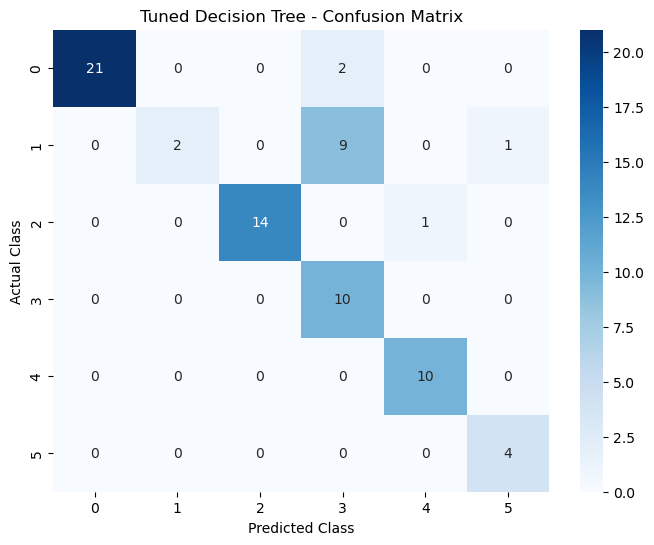

In [144]:
cm_dt = confusion_matrix(y_test, y_pred_dt_tuned)  # Create confusion matrix for the tuned Decision Tree model

plt.figure(figsize=(8, 6))  # Set figure size

sns.heatmap(
    cm_dt,  # Provide confusion matrix data
    annot=True,  # Display values inside each cell
    fmt="d",  # Format values as integers
    cmap="Blues"  # Apply blue color scheme
)

plt.title("Tuned Decision Tree - Confusion Matrix")  # Add chart title
plt.xlabel("Predicted Class")  # Label x-axis
plt.ylabel("Actual Class")  # Label y-axis
plt.show()  # Display confusion matrix

# Random Forest

In [145]:
from sklearn.ensemble import RandomForestClassifier  # Import Random Forest classification algorithm

In [146]:
rf_model = RandomForestClassifier(random_state=42)  # Initialize Random Forest model with a fixed random state
rf_model  # Display the model configuration

RandomForestClassifier(random_state=42)

In [147]:
rf_model.fit(X_train_selected, y_train_smote)  # Train the Random Forest model using the training data
print("Random Forest Model Created Successfully")  # Display success message

Random Forest Model Created Successfully


In [148]:
y_pred_rf = rf_model.predict(X_test_selected)  # Predict skin disorder classes using the Random Forest model
y_pred_rf  # Display predicted results

array([2, 3, 4, 1, 4, 3, 4, 1, 2, 3, 1, 5, 5, 3, 5, 6, 6, 1, 5, 3, 1, 4,
       1, 1, 2, 3, 4, 1, 6, 2, 4, 5, 6, 2, 3, 1, 3, 5, 1, 1, 4, 1, 4, 1,
       1, 4, 1, 1, 5, 5, 1, 1, 1, 4, 3, 3, 1, 6, 4, 1, 1, 3, 5, 5, 2, 3,
       3, 4, 1, 3, 2, 4, 4, 5])

### Model Evaluation

In [149]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)  # Calculate Random Forest model accuracy

In [150]:
rf_precision = precision_score(y_test, y_pred_rf, average="weighted")# Calculate weighted precision for the Random Forest model

In [151]:
rf_recall = recall_score(y_test, y_pred_rf, average="weighted")# Calculate weighted recall for the Random Forest model

In [152]:
rf_f1 = f1_score(y_test, y_pred_rf, average="weighted")# Calculate weighted F1-score for the Random Forest model

In [153]:
print("Random Forest Model Evaluation Results")  # Display evaluation heading
print("-----------------")  # Print separator
print("Accuracy :", rf_accuracy)  # Display accuracy
print("Precision:", rf_precision)  # Display precision
print("Recall   :", rf_recall)  # Display recall
print("F1 Score :", rf_f1)  # Display F1-score

Random Forest Model Evaluation Results
-----------------
Accuracy : 0.8918918918918919
Precision: 0.9054756054756055
Recall   : 0.8918918918918919
F1 Score : 0.8870415009253484


In [154]:
rf_CR = classification_report(y_test, y_pred_rf)# Generate classification report for the Random Forest model
print(rf_CR)  # Display precision, recall, F1-score, and support for each class

              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       0.86      0.50      0.63        12
           3       1.00      0.93      0.97        15
           4       0.64      0.90      0.75        10
           5       0.91      1.00      0.95        10
           6       0.80      1.00      0.89         4

    accuracy                           0.89        74
   macro avg       0.87      0.89      0.86        74
weighted avg       0.91      0.89      0.89        74



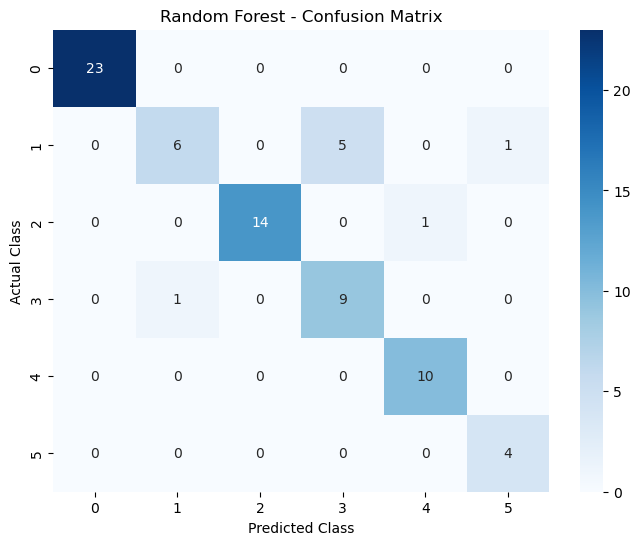

In [155]:
cm_rf = confusion_matrix(y_test, y_pred_rf)  # Create confusion matrix for the Random Forest model
plt.figure(figsize=(8, 6))  # Set figure size
sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Blues")  # Display confusion matrix as a heatmap
plt.title("Random Forest - Confusion Matrix")  # Add chart title
plt.xlabel("Predicted Class")  # Label x-axis
plt.ylabel("Actual Class")  # Label y-axis
plt.show()  # Display the confusion matrix

### Random Forest with Hyperparameter Tuning

In [156]:
rf_param_grid = {  # Define hyperparameter values for Random Forest tuning
    "n_estimators": [100, 200, 300],  # Set the number of decision trees in the forest
    "max_depth": [None, 5, 10, 15],  # Set maximum depth of each tree; None allows unlimited depth
    "min_samples_split": [2, 5, 10],  # Set minimum samples required to split an internal node
    "min_samples_leaf": [1, 2, 4]  # Set minimum samples required at a leaf node
}

In [157]:
rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),  # Initialize Random Forest classifier
    param_grid=rf_param_grid,  # Provide hyperparameter combinations to test
    cv=5,  # Apply 5-fold cross-validation
    scoring="f1_weighted",  # Select the model with the best weighted F1-score
    n_jobs=-1  # Use all available CPU cores
)  # Configure GridSearchCV for hyperparameter tuning

In [158]:
rf_grid.fit(
    X_train_selected,  # Provide selected training features
    y_train_smote  # Provide SMOTE-resampled training target labels
)

print("Random Forest Hyperparameter Tuning Completed")  # Display completion message

Random Forest Hyperparameter Tuning Completed


In [159]:
print("Best Parameters:")  # Display the best hyperparameter settings
print(rf_grid.best_params_)  # Show the best parameter combination

print("Best Cross Validation F1 Score:")  # Display the best cross-validation F1-score
print(rf_grid.best_score_)  # Show the highest weighted F1-score from cross-validation

Best Parameters:
{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}
Best Cross Validation F1 Score:
0.9641537399484177


In [160]:
rf_tuned = rf_grid.best_estimator_  # Select the best-tuned Random Forest model
rf_tuned  # Display the tuned model and its best hyperparameters

RandomForestClassifier(n_estimators=300, random_state=42)

In [161]:
y_pred_rf_tuned = rf_tuned.predict(X_test_selected)  # Predict skin disorder classes using the tuned Random Forest model
y_pred_rf_tuned  # Display the predicted results

array([2, 3, 4, 1, 4, 3, 4, 1, 2, 3, 1, 5, 5, 3, 5, 6, 6, 1, 5, 3, 1, 4,
       1, 1, 4, 3, 4, 1, 6, 4, 4, 5, 6, 2, 3, 1, 3, 5, 1, 1, 4, 1, 4, 1,
       1, 4, 1, 1, 5, 5, 1, 1, 1, 4, 3, 3, 1, 6, 4, 1, 1, 3, 5, 5, 2, 3,
       3, 4, 1, 3, 4, 4, 4, 5])

### Model Evulation With Hyper Parameter Tunning

In [162]:
rf_tuned_accuracy = accuracy_score(y_test, y_pred_rf_tuned)# Calculate accuracy of the tuned Random Forest model

In [163]:
rf_tuned_precision = precision_score(y_test, y_pred_rf_tuned, average="weighted")# Calculate weighted precision for the tuned Random Forest model

In [164]:
rf_tuned_recall = recall_score(y_test, y_pred_rf_tuned, average="weighted")# Calculate weighted recall for the tuned Random Forest model

In [165]:
rf_tuned_f1 = f1_score(y_test, y_pred_rf_tuned, average="weighted")# Calculate weighted F1-score for the tuned Random Forest model

In [166]:
# Display the evaluation results of the tuned Random Forest model
print("Random Forest Model Evaluation with Hyperparameter Tuning Results")

print("---------------------------")  # Print a separator line

print("Accuracy :", rf_tuned_accuracy)  # Display the accuracy score
print("Precision:", rf_tuned_precision)  # Display the weighted precision score
print("Recall   :", rf_tuned_recall)  # Display the weighted recall score
print("F1 Score :", rf_tuned_f1)  # Display the weighted F1-score

Random Forest Model Evaluation with Hyperparameter Tuning Results
---------------------------
Accuracy : 0.8783783783783784
Precision: 0.9212602977308859
Recall   : 0.8783783783783784
F1 Score : 0.8644531230738128


In [167]:
Rf_tuned_CR = classification_report(y_test, y_pred_rf_tuned)# Generate the classification report for the tuned Random Forest model
print(Rf_tuned_CR)# Display precision, recall, F1-score, and support for each class

              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       1.00      0.33      0.50        12
           3       1.00      0.93      0.97        15
           4       0.59      1.00      0.74        10
           5       0.91      1.00      0.95        10
           6       0.80      1.00      0.89         4

    accuracy                           0.88        74
   macro avg       0.88      0.88      0.84        74
weighted avg       0.92      0.88      0.86        74



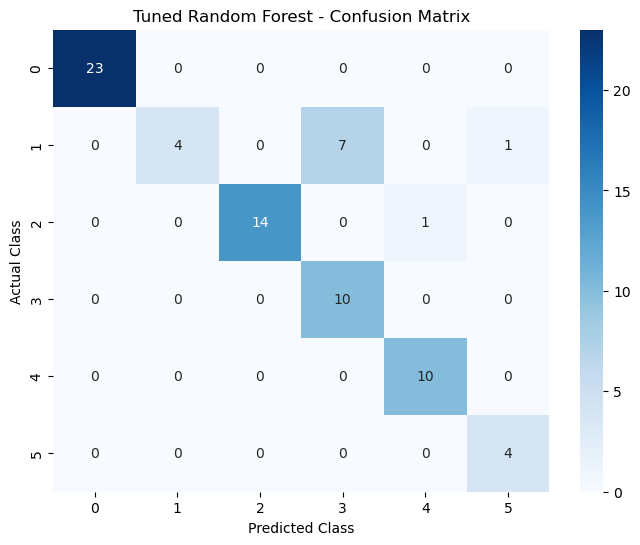

In [168]:
cm_rf_tuned = confusion_matrix(y_test, y_pred_rf_tuned)# Calculate the confusion matrix for the tuned Random Forest model
plt.figure(figsize=(8, 6))# Set the size of the confusion matrix plot
sns.heatmap(cm_rf_tuned, annot=True, fmt="d", cmap="Blues") # Display the confusion matrix as a heatmap with integer values
plt.title("Tuned Random Forest - Confusion Matrix") # Add a title to the confusion matrix
plt.xlabel("Predicted Class")# Label the x-axis with predicted classes
plt.ylabel("Actual Class")# Label the y-axis with actual classes
plt.show()# Display the confusion matrix plot

### SVM

In [169]:
from sklearn.svm import SVC  # Import Support Vector Classifier (SVC) for classification

In [170]:
svm_model = SVC(random_state=42)  # Create an SVM classification model with a fixed random state

svm_model  # Display the SVM model configuration

SVC(random_state=42)

In [171]:
svm_model.fit(X_train_selected, y_train_smote) # Train the SVM model using the selected training features and SMOTE-balanced target data
print("SVM Model Created Successfully")# Display a success message after training the model

SVM Model Created Successfully


In [172]:
y_pred_svm = svm_model.predict(X_test_selected) # Predict the classes for the test dataset using the trained SVM model
y_pred_svm # Display the predicted class labels

array([6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6,
       6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6,
       6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6,
       6, 6, 6, 6, 6, 6, 6, 6])

### Model Evalution

In [173]:
svm_accuracy = accuracy_score(y_test, y_pred_svm)# Calculate the accuracy score of the SVM model

In [174]:
svm_precision = precision_score(y_test, y_pred_svm, average="weighted")# Calculate weighted precision for the SVM model

In [175]:
svm_recall = recall_score(y_test, y_pred_svm, average="weighted")# Calculate weighted recall for the SVM model

In [176]:
svm_f1 = f1_score(y_test, y_pred_svm, average="weighted")# Calculate weighted F1-score for the SVM model

In [177]:
print("SVM Model Evaluation Results") # Display the evaluation results of the SVM model
print("-----------------")  # Print a separator line
print("Accuracy :", svm_accuracy)  # Display the accuracy score
print("Precision:", svm_precision)  # Display the weighted precision score
print("Recall   :", svm_recall)  # Display the weighted recall score
print("F1 Score :", svm_f1)  # Display the weighted F1-score

SVM Model Evaluation Results
-----------------
Accuracy : 0.05405405405405406
Precision: 0.0029218407596785976
Recall   : 0.05405405405405406
F1 Score : 0.005544005544005544


In [178]:
SVM_CR = classification_report(y_test, y_pred_svm) # Generate the classification report for the SVM model
print(SVM_CR) # Display precision, recall, F1-score, and support for each class

              precision    recall  f1-score   support

           1       0.00      0.00      0.00        23
           2       0.00      0.00      0.00        12
           3       0.00      0.00      0.00        15
           4       0.00      0.00      0.00        10
           5       0.00      0.00      0.00        10
           6       0.05      1.00      0.10         4

    accuracy                           0.05        74
   macro avg       0.01      0.17      0.02        74
weighted avg       0.00      0.05      0.01        74



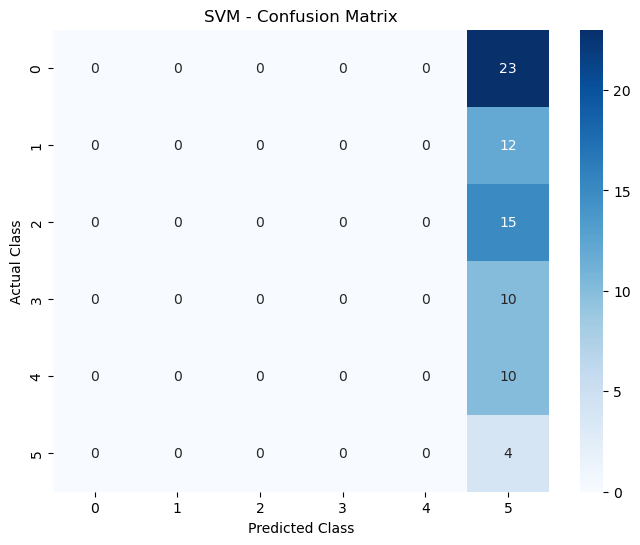

In [179]:
cm_svm = confusion_matrix(y_test, y_pred_svm) # Calculate the confusion matrix for the SVM model
plt.figure(figsize=(8, 6))# Set the size of the confusion matrix plot
sns.heatmap(cm_svm, annot=True, fmt="d", cmap="Blues") # Display the confusion matrix as a heatmap with integer values
plt.title("SVM - Confusion Matrix") # Add a title to the confusion matrix
plt.xlabel("Predicted Class") # Label the x-axis with predicted classes
plt.ylabel("Actual Class") # Label the y-axis with actual classes
plt.show() # Display the confusion matrix plot

### SVM With Hyperparameter Tuning

In [180]:
# Define the hyperparameter values to test for the SVM model
svm_param_grid = {
    "C": [0.1, 1, 10, 100],  # Test different regularization strengths
    "kernel": ["linear", "rbf", "poly"],  # Test different kernel functions
    "gamma": ["scale", "auto"]  # Test different gamma settings for kernel calculations
}

In [181]:
# Create GridSearchCV to find the best hyperparameters for the SVM model
svm_grid = GridSearchCV(
    estimator=SVC(random_state=42),  # Set the SVM classifier as the model
    param_grid=svm_param_grid,  # Provide the hyperparameter combinations to test
    cv=5,  # Use 5-fold cross-validation
    scoring="f1_weighted",  # Select the best model based on weighted F1-score
    n_jobs=-1  # Use all available CPU cores to speed up the search
)

In [182]:
svm_grid.fit(X_train_selected,y_train_smote) # Train GridSearchCV using the selected training features and SMOTE-balanced target data
print("SVM Hyperparameter Tuning Completed") # Display a message after hyperparameter tuning is completed

SVM Hyperparameter Tuning Completed


In [183]:
print("Best Parameters:")
print(svm_grid.best_params_) # Display the best hyperparameter combination found by GridSearchCV

print("Best Cross Validation F1 Score:")
print(svm_grid.best_score_) # Display the highest weighted F1-score achieved during cross-validation

Best Parameters:
{'C': 100, 'gamma': 'auto', 'kernel': 'rbf'}
Best Cross Validation F1 Score:
0.9587136307529536


In [184]:
svm_tuned = svm_grid.best_estimator_ # Store the best SVM model found during hyperparameter tuning
svm_tuned # Display the best-tuned SVM model

SVC(C=100, gamma='auto', random_state=42)

In [185]:
y_pred_svm_tuned = svm_tuned.predict(X_test_selected) # Predict the classes for the test dataset using the tuned SVM model
y_pred_svm_tuned # Display the predicted class labels

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1])

### Model Evulation With Hyper Parameter Tunning

In [186]:
svm_tuned_accuracy = accuracy_score(y_test,y_pred_svm_tuned)# Calculate the accuracy score of the tuned SVM model

In [187]:
svm_tuned_precision = precision_score(y_test,y_pred_svm_tuned,average="weighted")# Calculate weighted precision for the tuned SVM model

In [188]:
svm_tuned_recall = recall_score(y_test,y_pred_svm_tuned,average="weighted")# Calculate weighted recall for the tuned SVM model

In [189]:
svm_tuned_f1 = f1_score(y_test,y_pred_svm_tuned,average="weighted")# Calculate weighted F1-score for the tuned SVM model

In [190]:
print("SVM Model Evaluation with Hyperparameter Tuning Results") # Display the evaluation results of the tuned SVM model
print("-----------------")  # Print a separator line
print("Accuracy :", svm_tuned_accuracy)  # Display the accuracy score
print("Precision:", svm_tuned_precision)  # Display the weighted precision score
print("Recall   :", svm_tuned_recall)  # Display the weighted recall score
print("F1 Score :", svm_tuned_f1)  # Display the weighted F1-score

SVM Model Evaluation with Hyperparameter Tuning Results
-----------------
Accuracy : 0.3108108108108108
Precision: 0.09660336011687362
Recall   : 0.3108108108108108
F1 Score : 0.14739481749791028


In [191]:
SVM_CR = classification_report(y_test,y_pred_svm_tuned)# Generate the classification report for the tuned SVM model
print(SVM_CR)# Display precision, recall, F1-score, and support for each class

              precision    recall  f1-score   support

           1       0.31      1.00      0.47        23
           2       0.00      0.00      0.00        12
           3       0.00      0.00      0.00        15
           4       0.00      0.00      0.00        10
           5       0.00      0.00      0.00        10
           6       0.00      0.00      0.00         4

    accuracy                           0.31        74
   macro avg       0.05      0.17      0.08        74
weighted avg       0.10      0.31      0.15        74



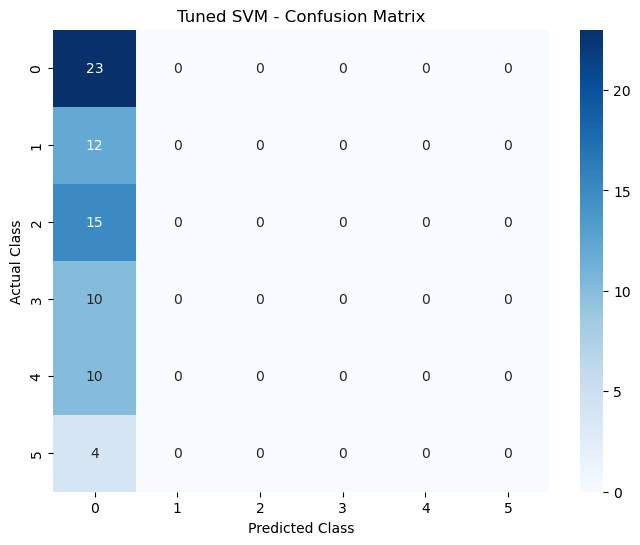

In [192]:
cm_svm_tuned = confusion_matrix(y_test,y_pred_svm_tuned) # Calculate the confusion matrix for the tuned SVM model
plt.figure(figsize=(8, 6))# Set the size of the confusion matrix plot
sns.heatmap(cm_svm_tuned,annot=True,fmt="d",cmap="Blues")# Display the confusion matrix as a heatmap with integer values
plt.title("Tuned SVM - Confusion Matrix")# Add a title to the confusion matrix
plt.xlabel("Predicted Class")# Label the x-axis with predicted classes
plt.ylabel("Actual Class")# Label the y-axis with actual classes
plt.show()# Display the confusion matrix plot

# MLP (Neural Network)

In [193]:
from sklearn.neural_network import MLPClassifier  # Import MLPClassifier for neural network-based classification

In [194]:
# Create the MLP neural network classification model
mlp_model = MLPClassifier(
    hidden_layer_sizes=(100,),  # Set one hidden layer containing 100 neurons
    activation="relu",  # Use ReLU activation function for the hidden layer
    solver="adam",  # Use the Adam optimizer to update model weights
    max_iter=1000,  # Allow up to 1000 iterations for model training
    random_state=42  # Set a fixed random state for reproducible results
)

In [195]:
mlp_model.fit(X_train_selected,y_train_smote) # Train the MLP neural network model using the selected training features and SMOTE-balanced target labels
print("MLP Model Created Successfully") # Display a success message after model training

MLP Model Created Successfully


In [196]:
y_pred_mlp = mlp_model.predict(X_test_selected) # Predict the classes for the test dataset using the trained MLP model
y_pred_mlp # Display the predicted class labels

array([2, 3, 4, 1, 4, 3, 4, 1, 4, 3, 1, 5, 5, 3, 5, 6, 1, 1, 5, 3, 1, 4,
       1, 1, 2, 3, 2, 1, 6, 2, 4, 5, 6, 2, 3, 1, 3, 5, 1, 1, 4, 1, 4, 1,
       1, 4, 1, 1, 3, 5, 1, 1, 1, 2, 3, 3, 1, 6, 4, 1, 1, 3, 5, 5, 2, 3,
       3, 4, 1, 3, 2, 4, 2, 5])

### Model Evaluation

In [197]:
mlp_accuracy = accuracy_score(y_test,y_pred_mlp)# Calculate the accuracy score of the MLP model

In [198]:
mlp_precision = precision_score(y_test,y_pred_mlp,average="weighted")# Calculate weighted precision for the MLP model

In [199]:
mlp_recall = recall_score(y_test,y_pred_mlp,average="weighted") # Calculate weighted recall for the MLP model

In [200]:
mlp_f1 = f1_score(y_test,y_pred_mlp,average="weighted")  # Calculate weighted F1-score for the MLP model

In [201]:
print("MLP in Model Evulation Results") # Display the evaluation results of the MLP model
print("-----------------") # Print a separator line
print("Accuracy :", mlp_accuracy)  # Display the accuracy score
print("Precision:", mlp_precision)  # Display the weighted precision score
print("Recall   :", mlp_recall)  # Display the weighted recall score
print("F1 Score :", mlp_f1)  # Display the weighted F1-score

MLP in Model Evulation Results
-----------------
Accuracy : 0.918918918918919
Precision: 0.9217342342342344
Recall   : 0.918918918918919
F1 Score : 0.9166934273317251


In [202]:
MLP_CR = classification_report(y_test,y_pred_mlp) # Generate the classification report for the MLP model
print(MLP_CR) # Display precision, recall, F1-score, and support for each class

              precision    recall  f1-score   support

           1       0.96      1.00      0.98        23
           2       0.89      0.67      0.76        12
           3       1.00      1.00      1.00        15
           4       0.75      0.90      0.82        10
           5       1.00      1.00      1.00        10
           6       0.75      0.75      0.75         4

    accuracy                           0.92        74
   macro avg       0.89      0.89      0.88        74
weighted avg       0.92      0.92      0.92        74



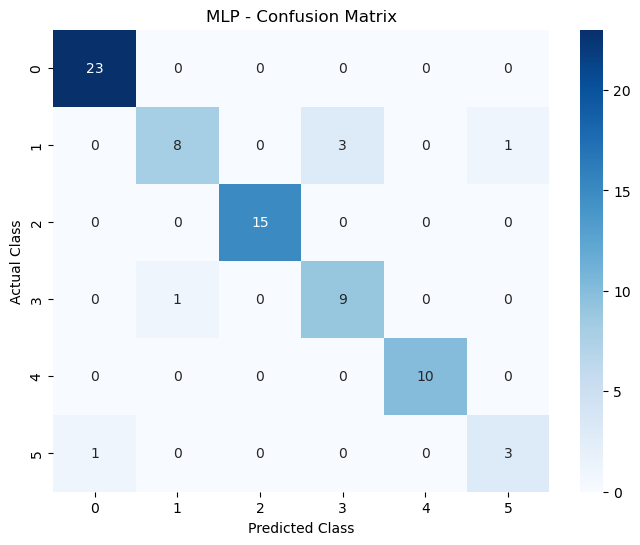

In [203]:
cm_mlp = confusion_matrix(y_test,y_pred_mlp) # Calculate the confusion matrix for the MLP model
plt.figure(figsize=(8, 6)) # Set the size of the confusion matrix plot
sns.heatmap(cm_mlp,annot=True,fmt="d",cmap="Blues") # Display the confusion matrix as a heatmap with integer values
plt.title("MLP - Confusion Matrix") # Add a title to the confusion matrix
plt.xlabel("Predicted Class") # Label he x-axis with predicted classes
plt.ylabel("Actual Class") # Label the y-axis with actual classes
plt.show() # Display the confusion matrix plot

### MLP With Hyperparameter Tuning

In [204]:
# Define the hyperparameter combinations to test for the MLP model
mlp_param_grid = {
    "hidden_layer_sizes": [
        (50,),       # Test one hidden layer with 50 neurons
        (100,),      # Test one hidden layer with 100 neurons
        (50, 50)     # Test two hidden layers with 50 neurons each
    ],
    "activation": [
        "relu",      # Use the ReLU activation function
        "tanh"       # Use the tanh activation function
    ],
    "solver": [
        "adam"       # Use the Adam optimizer for training
    ],
    "alpha": [
        0.0001,      # Test a small regularization strength
        0.001,       # Test a medium regularization strength
        0.01         # Test a higher regularization strength
    ],
    "learning_rate_init": [
        0.001,       # Test a lower initial learning rate
        0.01         # Test a higher initial learning rate
    ],
    "max_iter": [
        1000         # Allow up to 1000 training iterations
    ]
}

In [205]:
# Create GridSearchCV to find the best hyperparameters for the MLP model
mlp_grid = GridSearchCV(
    estimator=MLPClassifier(
        random_state=42  # Set a fixed random state for reproducible results
    ),
    param_grid=mlp_param_grid,  # Provide the hyperparameter combinations to test
    cv=5,  # Use 5-fold cross-validation
    scoring="f1_weighted",  # Select the best model based on weighted F1-score
    n_jobs=-1  # Use all available CPU cores to speed up the search
)

In [206]:
mlp_grid.fit(X_train_selected,y_train_smote) # Train GridSearchCV using the selected training features and SMOTE-balanced target data
print("MLP Hyperparameter Tuning Completed") # Display a message after hyperparameter tuning is completed

MLP Hyperparameter Tuning Completed


In [207]:
# Display the best hyperparameter combination found by GridSearchCV
print("Best Parameters:")
print(mlp_grid.best_params_)

# Display the best average weighted F1 score obtained during 5-fold cross-validation
print("Best Cross Validation F1 Score:")
print(mlp_grid.best_score_)

Best Parameters:
{'activation': 'relu', 'alpha': 0.01, 'hidden_layer_sizes': (50, 50), 'learning_rate_init': 0.001, 'max_iter': 1000, 'solver': 'adam'}
Best Cross Validation F1 Score:
0.9401448041627563


In [208]:
mlp_tuned = mlp_grid.best_estimator_ # Store the best-performing MLP model found during hyperparameter tuning
mlp_tuned # Display the tuned MLP model with its best hyperparameters

MLPClassifier(alpha=0.01, hidden_layer_sizes=(50, 50), max_iter=1000,
              random_state=42)

In [209]:
y_pred_mlp_tuned = mlp_tuned.predict(X_test_selected) # Predict the skin disorder classes for the test dataset using the tuned MLP model
y_pred_mlp_tuned # Display the predicted skin disorder classes from the tuned MLP model


array([2, 3, 4, 1, 4, 3, 4, 1, 4, 3, 1, 5, 5, 3, 5, 6, 6, 1, 5, 3, 1, 4,
       1, 1, 2, 3, 2, 1, 6, 2, 4, 5, 2, 2, 3, 1, 3, 6, 1, 1, 2, 1, 4, 1,
       1, 4, 1, 1, 6, 5, 1, 1, 1, 2, 3, 3, 1, 6, 4, 1, 1, 3, 5, 5, 2, 3,
       3, 4, 1, 3, 2, 4, 2, 5])

### Model Evaluation with Hyper Parameter Tunning

In [210]:
mlp_tuned_accuracy = accuracy_score(y_test,y_pred_mlp_tuned) # Calculate the accuracy of the tuned MLP model by comparing actual and predicted labels

In [211]:
mlp_tuned_precision = precision_score(y_test,y_pred_mlp_tuned,average="weighted")# Calculate th weighted precision of the tuned MLP model by comparing actual and predicted labels

In [212]:
mlp_tuned_recall = recall_score(y_test,y_pred_mlp_tuned,average="weighted")# Calculate the weighted recall of the tuned MLP model by comparing actual and predicted labels

In [213]:
mlp_tuned_f1 = f1_score(y_test,y_pred_mlp_tuned,average="weighted")# Calculate the weighted F1 score of the tuned MLP model using actual and predicted labels

In [214]:
print("MLP in Model Evulation with Hyper Parameter Tunning Results") # Display the evaluation results of the tuned MLP model
print("-----------------") # Print a separator line for better readability
print("Accuracy :", mlp_tuned_accuracy) # Display the accuracy score of the tuned MLP model
print("Precision:", mlp_tuned_precision) # Display the weighted precision score of the tuned MLP model
print("Recall   :", mlp_tuned_recall) # Display the weighted recall score of the tuned MLP model
print("F1 Score :", mlp_tuned_f1) # Display the weighted F1 score of the tuned MLP model

MLP in Model Evulation with Hyper Parameter Tunning Results
-----------------
Accuracy : 0.9054054054054054
Precision: 0.9156429156429158
Recall   : 0.9054054054054054
F1 Score : 0.9076593891633741


In [215]:
MLP_tuned_CR=classification_report(y_test,y_pred_mlp_tuned) # using the actual test labels and predicted labels
print(MLP_tuned_CR) # Display the classification report, including precision, recall, F1-score, and support for each class

              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       0.82      0.75      0.78        12
           3       1.00      0.93      0.97        15
           4       0.73      0.80      0.76        10
           5       1.00      0.90      0.95        10
           6       0.67      1.00      0.80         4

    accuracy                           0.91        74
   macro avg       0.87      0.90      0.88        74
weighted avg       0.92      0.91      0.91        74



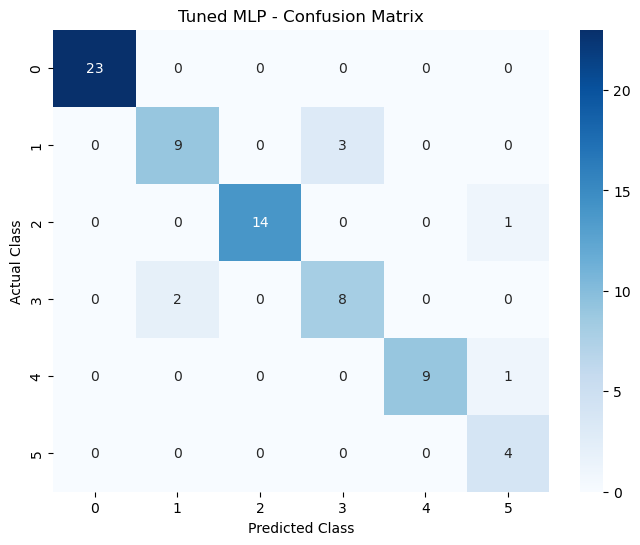

In [216]:
cm_mlp_tuned = confusion_matrix(y_test,y_pred_mlp_tuned)# Calculate the confusion matrix for the tuned MLP model
plt.figure(figsize=(8, 6)) # Set the figure size 
sns.heatmap(cm_mlp_tuned,annot=True,fmt="d",cmap="Blues")# Create a heatmap to visualize the confusion matrix
plt.title("Tuned MLP - Confusion Matrix") # Add a title to the confusion matrix
plt.xlabel("Predicted Class")# Label the x-axis with predicted class labels
plt.ylabel("Actual Class") # Label the y-axis with actual class labels
plt.show()# Display the confusion matrix heatmap

# Creating Model Comparison Report

In [217]:
# Create a DataFrame to compare the tuned performance of all six machine learning models
score = pd.DataFrame({
    # Store the names of the machine learning models
    "Model": [
        "LogisticRegression",
        "KNeighborsClassifier",
        "Support Vector Classifier",
        "DecisionTreeClassifier",
        "RandomForestClassifier",
        "ANN_MLPClassifier"
    ],

    # Store the tuned accuracy scores of each model
    "Accuracy": [
        lr_tuned_accuracy,
        knn_tuned_accuracy,
        dt_tuned_accuracy,
        rf_tuned_accuracy,
        svm_tuned_accuracy,
        mlp_tuned_accuracy
    ],

    # Store the tuned weighted precision scores of each model
    "Precision": [
        lr_tuned_precision,
        knn_tuned_precision,
        dt_tuned_precision,
        rf_tuned_precision,
        svm_tuned_precision,
        mlp_tuned_precision
    ],

    # Store the tuned weighted recall scores of each model
    "Recall": [
        lr_tuned_recall,
        knn_tuned_recall,
        dt_tuned_recall,
        rf_tuned_recall,
        svm_tuned_recall,
        mlp_tuned_recall
    ],

    # Store the tuned weighted F1 scores of each model
    "F1 Score": [
        lr_tuned_f1,
        knn_tuned_f1,
        dt_tuned_f1,
        rf_tuned_f1,
        svm_tuned_f1,
        mlp_tuned_f1
    ]
})

# Sort the models by F1 Score in descending order, placing the best score first
score = score.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

# Convert the evaluation scores into percentages and round them to two decimal places
for column in ["Accuracy", "Precision", "Recall", "F1 Score"]:
    score[column] = (score[column] * 100).round(2)

# Display the final comparison table of all tuned models
score

,Model,Accuracy,Precision,Recall,F1 Score
0,LogisticRegression,93.24,93.37,93.24,93.26
1,ANN_MLPClassifier,90.54,91.56,90.54,90.77
2,DecisionTreeClassifier,87.84,92.13,87.84,86.45
3,Support Vector Classifier,82.43,90.61,82.43,80.27
4,KNeighborsClassifier,52.70,68.12,52.70,52.94
5,RandomForestClassifier,31.08,9.66,31.08,14.74


In [218]:
best_model_name = score.loc[score["F1 Score"].idxmax(),"Model"] # Find the name of the model with the highest F1 Score
best_f1_score = score["F1 Score"].max() # Get the highest F1 Score from the comparison table
print("Best Model:", best_model_name) # Display the name of the best-performing model
print("Best F1 Score:", best_f1_score) # Display the highest F1 Score
print("Best F1 Score (%):", best_f1_score * 100) # Display the F1 Score as a percentage

Best Model: LogisticRegression
Best F1 Score: 93.26
Best F1 Score (%): 9326.0


# Conclusion of Model Comparison Report

The Skin Disorder Prediction project followed a complete machine learning workflow, including data understanding, exploratory data analysis, preprocessing, class imbalance handling, feature scaling, model development, hyperparameter tuning, and model evaluation.

The dataset contains six skin disorder classes with an imbalanced class distribution. Invalid values in the Age feature were handled using median imputation. SMOTE was incorporated into the training pipeline to address class imbalance without applying oversampling to the test data.

Multiple classification algorithms were evaluated, including Logistic Regression, KNN, SVM, Decision Tree, Random Forest, and ANN. Scaling was applied to models that are sensitive to feature magnitude, such as KNN, SVM, and ANN.

Hyperparameter tuning was performed using cross-validation. Model performance was evaluated using accuracy, precision, recall, weighted F1-score, classification reports, and confusion matrices.

The final model comparison was based on the test-set results and weighted F1-score rather than accuracy alone. The results should be interpreted carefully because model performance depends on the available dataset and may not directly generalize to unseen populations.

The developed system is a machine learning prediction model and should not be considered a replacement for professional medical diagnosis.

## Suggestions to the Doctors to identify the skin diseases of the patient at the earliest.

The exploratory analysis identifies associations between clinical/histopathological features and the six target classes. These observations can help understand patterns in the dataset; however, they should not be interpreted as independent medical diagnostic rules.

The machine learning model should be considered a predictive research tool and requires external validation before any real-world clinical application.

# Report on Challenges faced

This database contains 34 attributes, 33 of which are linear valued and one of them is nominal.this is a skin dieases dataset which 366 entries, 0 to 365 total columns and total 35 columns it has only one columns having object type and all of them are integers type. In this dataset most tough things are getting insights from data after working of 1 to 2 days I got insights.After thats every things are easy i did very easily and no more challenges I faced in this datasets.